# Does the simulator do what it says? — `data/` rebuilt by hand

`scripts/gen_mock_data.py` makes `data/` through the falcon nodes of `src/model.py`, which call
`src/functionlistnew.py`. This notebook recomputes every product **without that code**, in plain numpy
(float64), written out top to bottom with as few helper functions as possible, and compares each
result with the file in `data/`:

* every 2D comparison is a row of three panels: **data/ | mine | mine − data**;
* every 1D comparison: both curves, and **(mine − data) / max|data|**;
* the number printed is `max|mine − data| / max|data|`. `data/` is float32, so agreement is at the
  1e-7 level; a real mistake (wrong axis, sign, shift, factor) gives order 1.

Two things are checked from first principles rather than by repeating the code:

1. **The UV tracks** (`src/paddedAAstar_….pth`) are rebuilt from the station layout and Earth
   rotation (section 2). This settles which file row is u and which is v, and where DC sits.
2. **The Fourier transforms** are written as explicit DFT sums with the phase centre at pixel
   (64, 64) in the exponent, instead of `fft2` + `ifftshift` (sections 5 and 8).

The only project import is `src/settings.py` (pure constants), used to *check* the constants typed in below.

| § | step | compared with |
|---|---|---|
| 1 | index conventions: `array[y, x]`, FFT order | — (tests on toy images) |
| 2 | UV tracks from the layout | the tracks file |
| 3 | gains | `true_z` |
| 4 | UV coverage: integrations and baselines per cell | (internal checks) |
| 5 | δ, P(k), T_b, image | `true_delta`, `true_k`, `true_pk_measured`, `image` |
| 6 | Fourier sky (explicit DFT) | `np.fft`, point-source tests |
| 7 | visibilities → UV maps | `x_obs` |
| 8 | dirty images (explicit inverse DFT), orientation | `obsx_obs` |
| 9 | P(k) of the dirty images | `pk_obs` |
| 10 | calibrator: S_ref, V_ref, gains back | `S_ref`, `V_ref_obs` |
| 11 | dense science path | `S_obs`, `V_dense_obs` |

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from scipy.integrate import quad

# project root = first parent folder holding config.yml (works from notebooks/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
D = {f.stem: np.load(f) for f in sorted((ROOT / "data").glob("*.npy"))}
for name, arr in D.items():
    print(f"{name:18s} {str(arr.shape):14s} {arr.dtype}")

# torch is used only to load the tracks file and to redraw the seeded truth (z, δ). torch draws
# different random numbers on CPU and GPU for the same seed, so δ must be redrawn on the device
# that made data/.
DEV = str(D["mock_device"])
assert DEV == "cpu" or torch.cuda.is_available(), "data/ was made on a GPU: run this notebook on a GPU node"
print("\ndata/ was made on:", DEV)

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})

S_obs              (307, 307)     complex64
S_ref              (307, 307)     complex64
V_dense_obs        (307, 307)     complex64
V_ref_obs          (307, 307)     complex64
image              (128, 128)     float32
mock_device        ()             <U3
obsx_obs           (2, 128, 128)  float32
pk_obs             (2, 50)        float32
true_delta         (1, 128, 128)  float32
true_k             (50,)          float32
true_pk_measured   (50,)          float32
true_pw            (1, 4)         float64
true_z             (1, 212)       float32
x_obs              (2, 128, 128)  complex64

data/ was made on: cpu


In [2]:
# ---- set-up constants, typed in, then checked against src/settings.py
N, BOX = 128, 512.0                  # pixels per side, box side [Mpc]
DX = BOX / N                         # 4 Mpc per pixel
C = N // 2                           # 64: the image (beam / phase) centre pixel
Z_RED = 9.0                          # redshift
N_KNOWN = 200                        # stations with known gain g = 1
Z_SEED, Z_SCALE, FIELD_SEED = 99, 0.3, 54
TRUE_PW = (1.0, -0.5, -2.0, -0.8)    # log10 A, n1, n2, log10 k_break
CAL_FLUX, CAL_SIGMA = 2.7, 0.3       # calibrator peak [mK], width [px]
H, OM_M, OM_B, Y_P = 0.674, 0.315, 0.0492, 0.2454   # Planck 2018
N_BINS = 50                          # k-bins of the P(k) estimator

sys.path.insert(0, str(ROOT / "src")); import settings      # constants only, no simulator code
assert (N, BOX, Z_RED, N_KNOWN) == (settings.N_PIX, settings.BOX_SIZE, settings.REDSHIFT, settings.KNOWN_ANT)
assert (Z_SEED, Z_SCALE, FIELD_SEED, TRUE_PW) == (settings.TRUE_Z_SEED, settings.TRUE_Z_SCALE,
                                                  settings.TRUE_FIELD_SEED, settings.TRUE_PW)
assert (CAL_FLUX, CAL_SIGMA) == (settings.CALIBRATOR_FLUX, settings.CALIBRATOR_SIGMA)
assert (H, OM_M, OM_B, Y_P) == (settings.HUBBLE_H, settings.OMEGA_M, settings.OMEGA_B, settings.HELIUM_Y)
# what this notebook does NOT implement must be switched off in the set-up:
assert settings.NOISE_STD == 0, "thermal noise is on: this notebook rebuilds the noise-free data only"
assert settings.SCIENCE_FOREGROUND_FLUX == 0 and settings.N_SUBSETS == 2
assert tuple(D["true_pw"][0]) == TRUE_PW
print("constants agree with src/settings.py")

constants agree with src/settings.py


In [3]:
# ---- the comparison log and the two plotting helpers (they only display; no physics in here)
results = []                          # (name, max|mine − data| / max|data|)

def compare(name, mine, data):
    mine, data = np.asarray(mine), np.asarray(data)
    assert mine.shape == data.shape, f"{name}: shape {mine.shape} vs {data.shape}"
    nan = np.isnan(data)
    assert np.array_equal(np.isnan(mine), nan), f"{name}: NaNs in different places"
    rel = np.abs(mine[~nan] - data[~nan]).max() / np.abs(data[~nan]).max()
    results.append((name, rel))
    print(f"{name:30s} max|mine − data| / max|data| = {rel:.1e}")

def show3(data, mine, title, uv=False, labels=("x (column)", "y (row)"), cmap="viridis", norm=None):
    # data | mine | mine − data.  Complex arrays: |·|.  uv=True: the array is in FFT order and is
    # fftshifted FOR DISPLAY ONLY (DC in the middle, axes = signed u, v in cells).
    diff = mine - data
    is_complex = np.iscomplexobj(diff)
    data, mine = (np.abs(a) if np.iscomplexobj(a) else a for a in (data, mine))
    diff = np.abs(diff) if np.iscomplexobj(diff) else diff
    ext = None
    if uv:
        data, mine, diff = (np.fft.fftshift(a) for a in (data, mine, diff))
        ext = [-C - 0.5, C - 0.5, C - 0.5, -C - 0.5]
        labels = ("u [cells]", "v [cells]")
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    vmin, vmax = np.nanmin(data), np.nanmax(data)
    for a, img, t in ((ax[0], data, "data/"), (ax[1], mine, "mine")):
        im = a.imshow(img, cmap=cmap, norm=norm, vmin=None if norm else vmin, vmax=None if norm else vmax,
                      extent=ext, interpolation="nearest")
        a.set_title(f"{title}: {t}"); plt.colorbar(im, ax=a, fraction=0.046)
    d = np.nanmax(np.abs(diff)) or 1e-300
    im = ax[2].imshow(diff, cmap="RdBu_r", vmin=-d, vmax=d, extent=ext, interpolation="nearest")
    ax[2].set_title(f"|mine − data|  (max {d:.1e})" if is_complex else f"mine − data  (max {d:.1e})")
    plt.colorbar(im, ax=ax[2], fraction=0.046)
    for a in ax:
        a.set(xlabel=labels[0], ylabel=labels[1])
    plt.tight_layout(); plt.show()

def show_1d(k, data, mine, title, ylabel, loglog=True):
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    plot = ax[0].loglog if loglog else ax[0].semilogx
    plot(k, data, "o-", lw=3, ms=7, alpha=0.4, label="data/")
    plot(k, mine, "x--", color="C1", lw=1, label="mine")
    ax[0].set(xlabel="k [Mpc⁻¹]", ylabel=ylabel, title=title); ax[0].legend()
    ax[1].semilogx(k, (mine - data) / np.nanmax(np.abs(data)), "o", ms=4, color="C1")
    ax[1].axhline(0, color="gray", lw=0.8)
    ax[1].set(xlabel="k [Mpc⁻¹]", ylabel="(mine − data) / max|data|", title=f"{title}: difference")
    plt.tight_layout(); plt.show()

## 1. Index conventions: `array[y, x]` and FFT order

The worry: images are indexed `[row, column]`, physics talks about `(x, y)` and `(u, v)`, and the
FFT puts the largest scales (DC) at index `[0, 0]`, not in the middle. Here is what numpy (and torch,
which uses the same conventions) actually does, tested on toy images:

* `img[y, x]`: the **first index is the row (y, down)**, the second the **column (x, right)**;
  `imshow` draws row 0 at the top.
* `fft2(img)[a, b]`: index `a` is the frequency **along rows (v, conjugate to y)**, `b` along
  **columns (u, conjugate to x)** — the transform keeps the axis order. So a UV map is `uv[v, u]`.
* Index `b` holds frequency `fftfreq(N)[b] · N` cycles per box: `0, 1, …, 63, −64, −63, …, −1`.
  **DC (the box mean, the largest scale) is at `[0, 0]`; negative frequencies are wrapped to the
  end.** `np.fft.fftshift` only rearranges this for display (DC in the middle).

wave along x, 3 periods:  |fft2| peaks at [row, col] = [[0, 3], [0, 125]]
wave along y, 5 periods:  |fft2| peaks at [row, col] = [[5, 0], [123, 0]]
signed frequency of FFT index 0, 1, 2, …, 63, 64, 65, …, 127: [0, 1, 2, 63, -64, -63, -1]


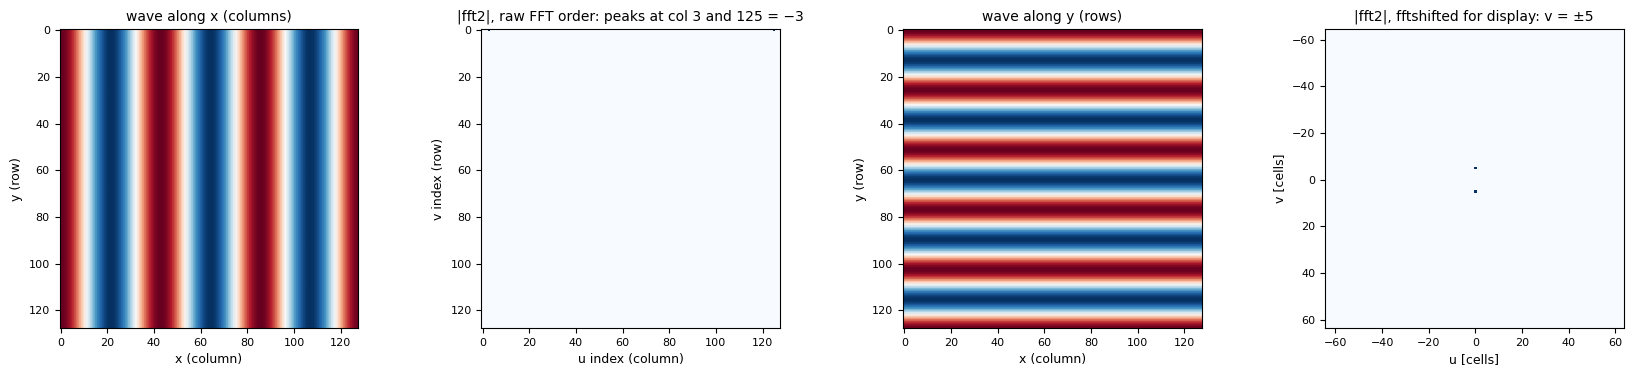

In [4]:
yy, xx = np.mgrid[0:N, 0:N]                  # yy = row index, xx = column index of every pixel
assert xx[0, 7] == 7 and yy[7, 0] == 7

wave_x = np.cos(2 * np.pi * 3 * xx / N)      # varies along x (columns): 3 periods per box
wave_y = np.cos(2 * np.pi * 5 * yy / N)      # varies along y (rows): 5 periods per box
for name, img in (("wave along x, 3 periods", wave_x), ("wave along y, 5 periods", wave_y)):
    F = np.abs(np.fft.fft2(img))
    print(f"{name}:  |fft2| peaks at [row, col] = {np.argwhere(F > 0.5 * F.max()).tolist()}")
print("signed frequency of FFT index 0, 1, 2, …, 63, 64, 65, …, 127:",
      (np.fft.fftfreq(N) * N).astype(int)[[0, 1, 2, 63, 64, 65, 127]].tolist())

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
ax[0].imshow(wave_x, cmap="RdBu_r"); ax[0].set(title="wave along x (columns)", xlabel="x (column)", ylabel="y (row)")
ax[1].imshow(np.abs(np.fft.fft2(wave_x)), cmap="Blues", interpolation="nearest")
ax[1].set(title="|fft2|, raw FFT order: peaks at col 3 and 125 = −3", xlabel="u index (column)", ylabel="v index (row)")
ax[2].imshow(wave_y, cmap="RdBu_r"); ax[2].set(title="wave along y (rows)", xlabel="x (column)", ylabel="y (row)")
ax[3].imshow(np.fft.fftshift(np.abs(np.fft.fft2(wave_y))), cmap="Blues", interpolation="nearest",
             extent=[-C - 0.5, C - 0.5, C - 0.5, -C - 0.5])
ax[3].set(title="|fft2|, fftshifted for display: v = ±5", xlabel="u [cells]", ylabel="v [cells]")
plt.tight_layout(); plt.show()

**Result.** The x-wave appears in **columns** 3 and 125 (= −3) of row 0, the y-wave in **rows** 5 and
123 (= −5) of column 0. So `uv[v, u]`: rows are v, columns are u, DC at `[0, 0]`, negative
frequencies at the end. Everything below uses this, and section 2 checks that the tracks file
uses it too.

## 2. The UV tracks, rebuilt from the station layout

The tracks file holds, for every baseline (station pair i < j in `triu` order), its track over the
4 h on the 128 × 128 grid: shape `(K, 3, L)` with file rows `[0]`, `[1]`, `[2]` = the project's
"x (column)", "y (row)", "t (integrations of 30 s in that cell)", zero-padded to L = 52.

It was made with tools21cm 2.4.3 (`get_full_uv_map_with_antenna_stamp(128, 9, "AA*", 4, 30, 512)`),
with its constants set to Planck 2018, exact c and ν21. The recipe, rewritten here:

1. station positions: ENU [m] (`src/skalow_AAstar_layout.txt`) → tools21cm's XYZ frame
   (ENU → Earth-centred → rotated to the array's longitude), about the array centre
   (lon 116.764448°, lat −26.824722°);
2. baseline (i, j) = (r_i − r_j) / λ, λ = 0.21106 m × (1 + z);
3. Earth rotation: hour angle H = −2 h … +2 h in 30 s steps (480 integrations), declination −30°,
   `u = sin H·Bx + cos H·By`, `v = −sin δ cos H·Bx + sin δ sin H·By + cos δ·Bz`;
4. **cell = round(u × box / D_c(z))** (one UV cell = 1 / field of view), D_c(9) for Planck 2018;
5. keep cells with −64 ≤ cell < 64; tools21cm stores them as `map[t, cell_u, cell_v]`, so a
   negative cell lands at index cell + 128 (Python's `a[-3] = a[125]`). **This wrap is exactly FFT
   order** — the tracks were never centred on the grid, DC is at `[0, 0]` from the start.

In [5]:
padded = torch.load(ROOT / "src/paddedAAstar_4_30_9_128_512.pth", map_location="cpu", weights_only=True).numpy()
K, _, L = padded.shape
NANT = int(round((1 + np.sqrt(1 + 8 * K)) / 2)); assert NANT * (NANT - 1) // 2 == K
N_UNK = NANT - 1 - N_KNOWN
I, J = np.triu_indices(NANT, k=1)            # baseline b = (I[b], J[b]), i < j (same order as torch.triu_indices)
col, row, t = padded[:, 0].astype(int), padded[:, 1].astype(int), padded[:, 2]   # file rows 0, 1, 2
bl = np.broadcast_to(np.arange(K)[:, None], t.shape)                            # baseline of every track sample
print(f"{K} baselines, L = {L} → {NANT} stations: 1 reference + {N_UNK} unknown + {N_KNOWN} known")

# 1. stations: ENU → tools21cm XYZ
enu = np.loadtxt(ROOT / "src/skalow_AAstar_layout.txt")
lon, lat = np.deg2rad(116.764448), np.deg2rad(-26.824722)
R_enu_to_ecef = np.array([[-np.sin(lon), -np.sin(lat) * np.cos(lon), np.cos(lat) * np.cos(lon)],
                          [ np.cos(lon), -np.sin(lat) * np.sin(lon), np.cos(lat) * np.sin(lon)],
                          [ 0.0,          np.cos(lat),                np.sin(lat)]])
R_ecef_to_xyz = np.array([[ np.cos(lon), np.sin(lon), 0.0],
                          [-np.sin(lon), np.cos(lon), 0.0],
                          [ 0.0,         0.0,         1.0]])
xyz = enu @ R_enu_to_ecef.T @ R_ecef_to_xyz.T

# 2. baselines in wavelengths; 4. cell size, Planck 2018 with exact c and ν21
C_KMS, NU21 = 299792.458, 1420.405751768e6
D_C = C_KMS / (100 * H) * quad(lambda z: 1 / np.sqrt(OM_M * (1 + z) ** 3 + 1 - OM_M), 0, Z_RED)[0]   # [Mpc]
LAM = C_KMS * 1e3 / (NU21 / (1 + Z_RED))                                                            # [m]
print(f"D_c({Z_RED:.0f}) = {D_C:.2f} Mpc, λ = {LAM:.5f} m → one UV cell = {D_C / BOX:.2f} wavelengths "
      f"= {D_C / BOX * LAM:.1f} m of baseline")
B = (xyz[I] - xyz[J]) / LAM                                                   # (K, 3)

# 3. Earth rotation
HA = np.deg2rad(15 * (-2 * 3600 + 30 * np.arange(480)) / 3600)[:, None]      # (480, 1) hour angle
DEC = np.deg2rad(-30.0)
u = np.sin(HA) * B[:, 0] + np.cos(HA) * B[:, 1]                                # (480, K) [wavelengths]
v = -np.sin(DEC) * np.cos(HA) * B[:, 0] + np.sin(DEC) * np.sin(HA) * B[:, 1] + np.cos(DEC) * B[:, 2]

# 4.-5. signed cells, kept if on the grid, wrapped to FFT order
cell_u = np.round(u * BOX / D_C).astype(int)
cell_v = np.round(v * BOX / D_C).astype(int)
on_grid = (cell_u >= -C) & (cell_u < C) & (cell_v >= -C) & (cell_v < C)
b_rebuilt = np.broadcast_to(np.arange(K), cell_u.shape)[on_grid]

# compare as a table: one entry per (baseline, row, column) with its summed integrations
def per_cell(b, r, c, w):
    keys, inverse = np.unique((b * N + r) * N + c, return_inverse=True)
    return keys, np.bincount(inverse, weights=w)

used = t > 0
keys_file, t_file = per_cell(bl[used], row[used], col[used], t[used])
for name, r_, c_ in (("rows = v, columns = u (the project's convention)", cell_v, cell_u),
                     ("rows = u, columns = v (the other way round)", cell_u, cell_v)):
    keys_reb, t_reb = per_cell(b_rebuilt, r_[on_grid] % N, c_[on_grid] % N, np.ones(on_grid.sum()))
    same = np.array_equal(keys_reb, keys_file) and np.array_equal(t_reb, t_file)
    overlap = np.isin(keys_reb, keys_file).mean()
    print(f"{name}: {len(keys_reb)} entries, {overlap:.1%} of them in the file; identical to the file: {same}")
    if r_ is cell_v:
        assert same, "the rebuilt tracks differ from the tracks file"
print(f"(the file has {used.sum() - len(keys_file)} more rows than entries: a track that leaves a cell "
      f"and comes back gets a second row; the simulator sums them, so the table above sums them too)")

46971 baselines, L = 52 → 307 stations: 1 reference + 106 unknown + 200 known
D_c(9) = 9400.70 Mpc, λ = 2.11061 m → one UV cell = 18.36 wavelengths = 38.8 m of baseline


rows = v, columns = u (the project's convention): 308907 entries, 100.0% of them in the file; identical to the file: True


rows = u, columns = v (the other way round): 308907 entries, 6.9% of them in the file; identical to the file: False
(the file has 300 more rows than entries: a track that leaves a cell and comes back gets a second row; the simulator sums them, so the table above sums them too)


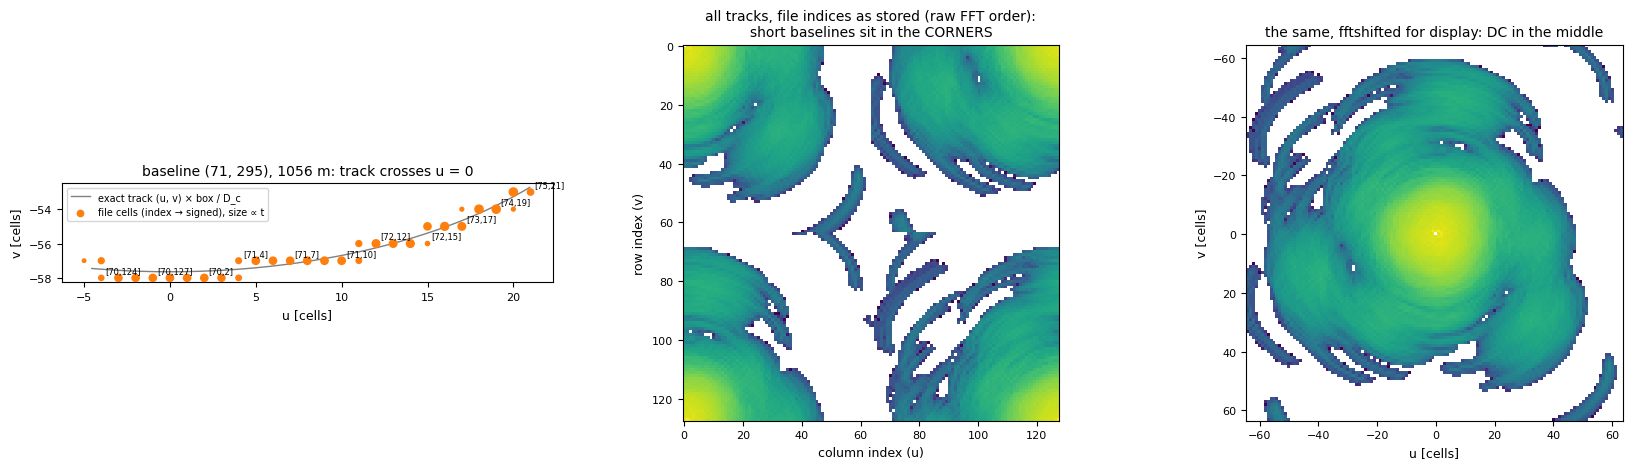

In [6]:
# one baseline, to see the wrap: a full 4 h track that crosses u = 0 at negative v, the one with most cells
crosses = (cell_u.min(0) < 0) & (cell_u.max(0) > 0) & (cell_v.max(0) < 0) & (t.sum(1) == 480)
b = np.flatnonzero(crosses)[np.argmax((t > 0).sum(1)[crosses])]
signed = lambda idx: np.where(idx >= C, idx - N, idx)            # FFT index → signed cell
m = t[b] > 0

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(u[:, b] * BOX / D_C, v[:, b] * BOX / D_C, color="gray", lw=1, label="exact track (u, v) × box / D_c")
ax[0].scatter(signed(col[b][m]), signed(row[b][m]), s=30 * t[b][m] / t[b][m].max() + 5, color="C1", zorder=3,
              label="file cells (index → signed), size ∝ t")
ax[0].set(xlabel="u [cells]", ylabel="v [cells]", aspect="equal",
          title=f"baseline ({I[b]}, {J[b]}), {np.hypot(*B[b, :2]) * LAM:.0f} m: track crosses u = 0")
ax[0].legend(fontsize=7)
for i_ in range(0, m.sum(), 3):
    ax[0].annotate(f"[{row[b][m][i_]},{col[b][m][i_]}]", (signed(col[b][m][i_]), signed(row[b][m][i_])),
                   fontsize=6, xytext=(3, 3), textcoords="offset points")

cover = np.zeros((N, N)); np.add.at(cover, (row[used], col[used]), t[used])   # integrations per cell, one copy per baseline
ax[1].imshow(np.where(cover > 0, cover, np.nan), norm=LogNorm(), cmap="viridis", interpolation="nearest")
ax[1].set(title="all tracks, file indices as stored (raw FFT order):\nshort baselines sit in the CORNERS",
          xlabel="column index (u)", ylabel="row index (v)")
ax[2].imshow(np.fft.fftshift(np.where(cover > 0, cover, np.nan)), norm=LogNorm(), cmap="viridis",
             interpolation="nearest", extent=[-C - 0.5, C - 0.5, C - 0.5, -C - 0.5])
ax[2].set(title="the same, fftshifted for display: DC in the middle", xlabel="u [cells]", ylabel="v [cells]")
plt.tight_layout(); plt.show()

**Result.** The tracks rebuilt from the station layout and Earth rotation are **identical** to the
file — every (baseline, cell) entry and every integration count — with **rows = v and columns = u**,
negative cells wrapped to the end (FFT order, DC at `[0, 0]`). The other assignment matches only the
cells near the u = v diagonal. In the left panel the exact track runs through u = 0 and the file's
cells follow it: cells with u < 0 are stored at column index u + 128 and cells with v < 0 at row
index v + 128 (the labels are `[row, column]` as stored). In raw index order (middle) the
dense short-baseline coverage sits in the four corners — exactly where `fft2` puts the large scales.
So the tracks and the FFT of the image use the same grid, with no shift between them.

## 3. Gains

`z` = 212 numbers: interleaved (Re, Im) perturbations of the 106 unknown stations, drawn N(0, 0.3²)
with seed 99. Station 0 is the reference (g = 1), stations 1–106 have g = 1 + z_re + i z_im,
stations 107–306 are known (g = 1). Baseline (i, j) multiplies the sky by `g_i conj(g_j)`.

z (redrawn from seed 99)       max|mine − data| / max|data| = 0.0e+00


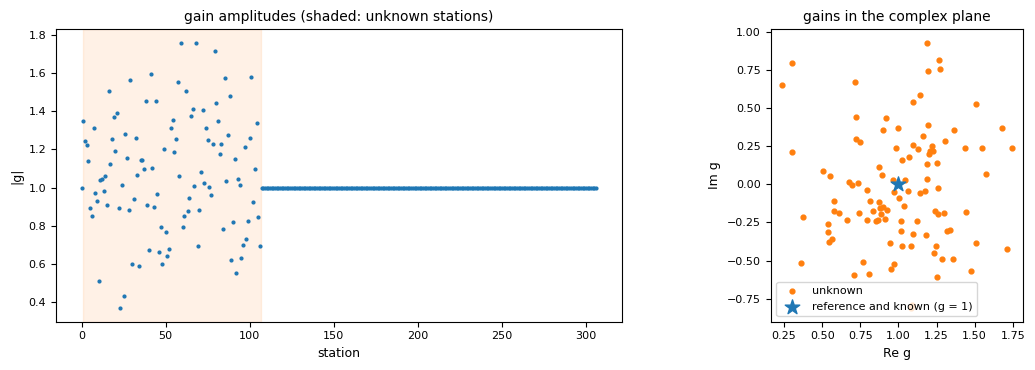

In [7]:
z_redrawn = torch.randn(1, 2 * N_UNK, generator=torch.Generator().manual_seed(Z_SEED)) * Z_SCALE
compare("z (redrawn from seed 99)", z_redrawn.numpy(), D["true_z"])

z_true = D["true_z"][0].astype(np.float64)
g = np.ones(NANT, dtype=complex)
g[1:1 + N_UNK] = (1 + z_true[0::2]) + 1j * z_true[1::2]
bg = g[I] * np.conj(g[J])                                        # (K,) gain product of every baseline

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(np.abs(g), ".", ms=4); ax[0].axvspan(0.5, N_UNK + 0.5, color="C1", alpha=0.1)
ax[0].set(xlabel="station", ylabel="|g|", title="gain amplitudes (shaded: unknown stations)")
ax[1].scatter(g.real[1:1 + N_UNK], g.imag[1:1 + N_UNK], s=12, color="C1", label="unknown")
ax[1].scatter([1], [0], marker="*", s=120, label="reference and known (g = 1)")
ax[1].set(xlabel="Re g", ylabel="Im g", aspect="equal", title="gains in the complex plane"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. UV coverage: integrations and baselines per cell

The baselines are split into **2 subsets** = the first and second half of the `triu` order
(23 486 and 23 485 baselines), one UV map each. Every track sample (baseline b, cell `[v, u]`,
t integrations) is put on the grid **twice**: as baseline (i, j) at `[v, u]` and as the reversed
baseline (j, i) at the mirrored cell `[−v, −u]` (both mod 128). Samples on the DC cell `[0, 0]` are
dropped (so the dirty images have zero mean). `counts[s, v, u]` = the number of 30 s integrations in
each cell — the normalisation of the UV maps.

Checks: the total equals 2 × Σ (integrations of each baseline); the map is point-symmetric; a full
4 h track has 480 integrations; and per cell, integrations ≤ 480 × (number of baselines in it).

In [8]:
SUBSET = (np.arange(K) >= (K + 1) // 2).astype(int)              # subset of each baseline: 0 = first half
print("baselines per subset:", np.bincount(SUBSET).tolist())

# every track sample once (duplicates of a cell are fine: they are summed)
b_s, r_s, c_s, t_s = bl[used], row[used], col[used], t[used].astype(np.float64)
t_s = np.where((r_s == 0) & (c_s == 0), 0.0, t_s)                # drop samples on the DC cell
s_s = SUBSET[b_s]
r_m, c_m = (-r_s) % N, (-c_s) % N                                # mirrored cell [−v, −u] of baseline (j, i)

counts = np.zeros((2, N, N))
np.add.at(counts, (s_s, r_s, c_s), t_s)
np.add.at(counts, (s_s, r_m, c_m), t_s)

# number of different baselines in each cell (each (baseline, cell) entry once, plus its mirror)
kb, kr, kc = keys_file // (N * N), (keys_file // N) % N, keys_file % N
keep = ~((kr == 0) & (kc == 0))
n_bl = np.zeros((2, N, N))
np.add.at(n_bl, (SUBSET[kb[keep]], kr[keep], kc[keep]), 1)
np.add.at(n_bl, (SUBSET[kb[keep]], (-kr[keep]) % N, (-kc[keep]) % N), 1)

n_per_bl = np.bincount(b_s, weights=t_s, minlength=K)            # integrations per baseline (DC dropped)
for s in range(2):
    print(f"subset {s}: Σ counts = {counts[s].sum():.0f},  2 × Σ integrations of its baselines = "
          f"{2 * n_per_bl[SUBSET == s].sum():.0f};  point-symmetric: "
          f"{np.array_equal(counts[s], np.roll(counts[s][::-1, ::-1], 1, axis=(0, 1)))};  "
          f"cells sampled {(counts[s] > 0).mean():.1%};  max integrations / (480 × baselines) = "
          f"{(counts[s][n_bl[s] > 0] / (480 * n_bl[s][n_bl[s] > 0])).max():.3f}")
assert all(counts[s].sum() == 2 * n_per_bl[SUBSET == s].sum() for s in range(2))
assert np.array_equal(counts > 0, n_bl > 0)
full = np.bincount(bl[used], weights=t[used], minlength=K)
print(f"integrations per baseline: {np.sum(full == 480)} full 4 h tracks (480), {np.sum(full == 0)} never on the grid, "
      f"{np.sum((full > 0) & (full < 480))} leave the grid part of the time")
print(f"union of both subsets: {((counts[0] > 0) | (counts[1] > 0)).mean():.1%} of the {N * N} cells sampled")

baselines per subset: [23486, 23485]
subset 0: Σ counts = 16014720,  2 × Σ integrations of its baselines = 16014720;  point-symmetric: True;  cells sampled 60.1%;  max integrations / (480 × baselines) = 0.552
subset 1: Σ counts = 9577810,  2 × Σ integrations of its baselines = 9577810;  point-symmetric: True;  cells sampled 76.3%;  max integrations / (480 × baselines) = 0.643
integrations per baseline: 26626 full 4 h tracks (480), 20246 never on the grid, 99 leave the grid part of the time
union of both subsets: 76.5% of the 16384 cells sampled


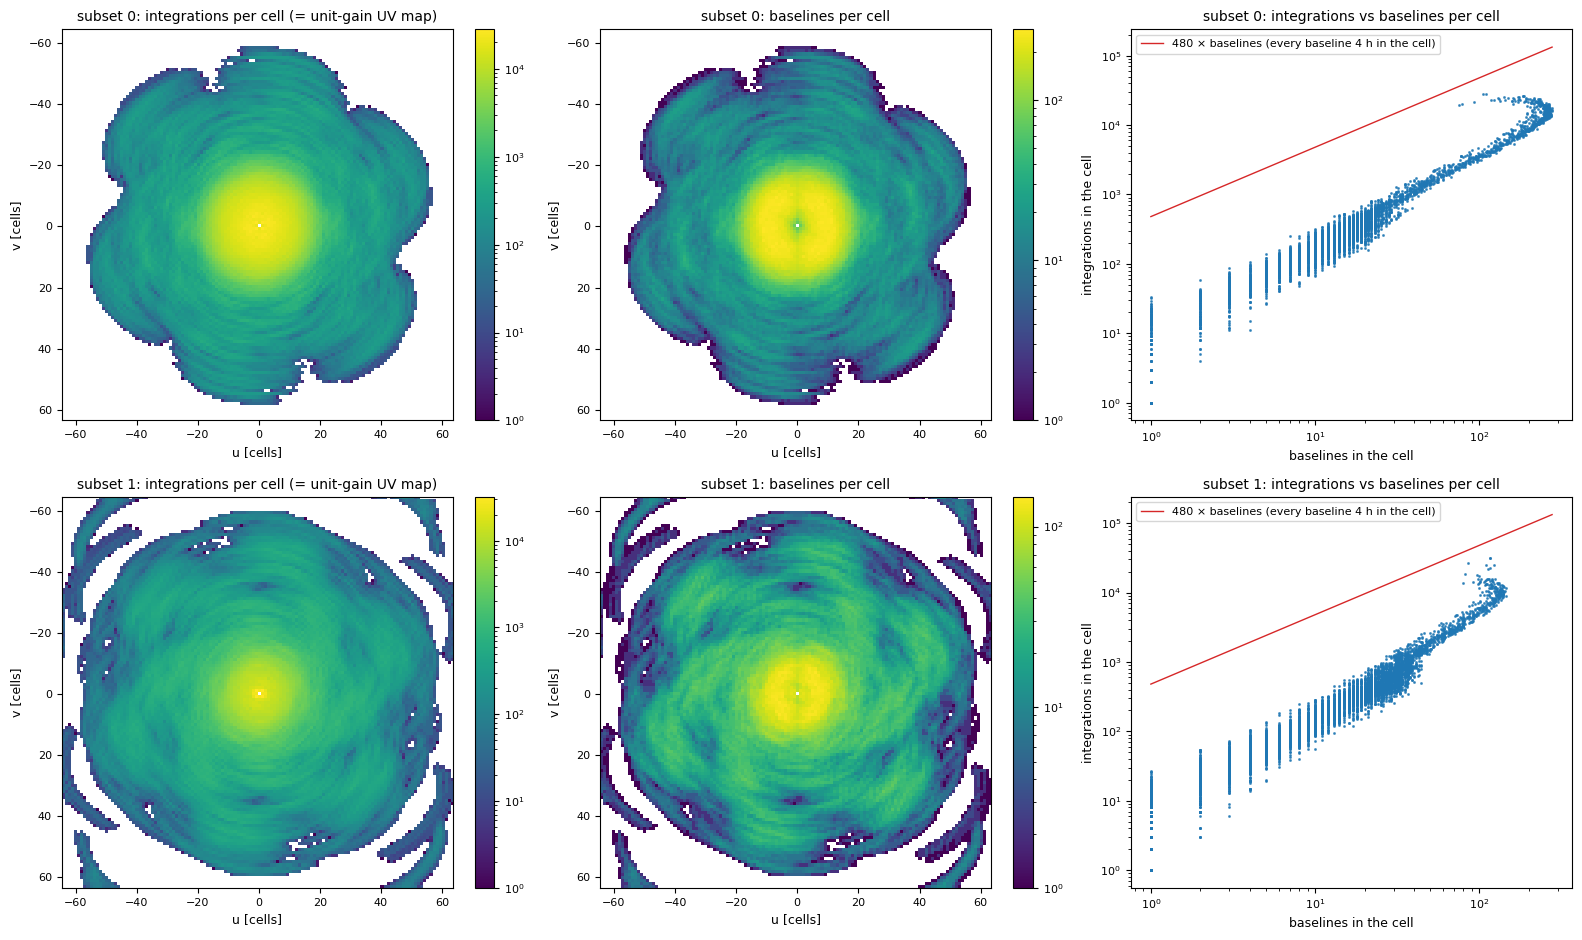

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))
ext = [-C - 0.5, C - 0.5, C - 0.5, -C - 0.5]
for s in range(2):
    sh = lambda a: np.fft.fftshift(np.where(counts[s] > 0, a, np.nan))
    im = ax[s, 0].imshow(sh(counts[s]), norm=LogNorm(), extent=ext, interpolation="nearest")
    ax[s, 0].set(title=f"subset {s}: integrations per cell (= unit-gain UV map)"); plt.colorbar(im, ax=ax[s, 0], fraction=0.046)
    im = ax[s, 1].imshow(sh(n_bl[s]), norm=LogNorm(), extent=ext, interpolation="nearest")
    ax[s, 1].set(title=f"subset {s}: baselines per cell"); plt.colorbar(im, ax=ax[s, 1], fraction=0.046)
    for a in ax[s, :2]:
        a.set(xlabel="u [cells]", ylabel="v [cells]")
    ok = counts[s] > 0
    ax[s, 2].loglog(n_bl[s][ok], counts[s][ok], ".", ms=2, alpha=0.5)
    nn = np.array([1, n_bl.max()])
    ax[s, 2].loglog(nn, 480 * nn, color="C3", lw=1, label="480 × baselines (every baseline 4 h in the cell)")
    ax[s, 2].set(xlabel="baselines in the cell", ylabel="integrations in the cell",
                 title=f"subset {s}: integrations vs baselines per cell"); ax[s, 2].legend()
plt.tight_layout(); plt.show()

**Result.** The integration map (the unit-gain UV map that normalises the science maps) is exactly
the sum of the baselines' integrations, twice (the mirrored copies), point-symmetric, and every cell
lies below the line "each of its baselines spends the whole 4 h in it": a baseline crosses several
cells, so most cells get a fraction of each baseline's 480 integrations. The dense centre holds
hundreds of baselines per cell, the edge one or two.

## 5. Sky: δ, its P(k), the brightness temperature

**δ.** The power spectrum is a broken power law, `P(k) = A (k/k_b)^n1` for k ≤ k_b and
`A (k/k_b)^n2` above, P(0) = 0. The field: real white noise (torch, seed 54) → `fft2` (ortho, unit
power per mode) → × `sqrt(P(|k|) / (dx dy))` → inverse `fft2`. Here on the full FFT plane, with
`|k|` built explicitly from `ky` along rows and `kx` along columns. (The project uses the half-plane
`rfft2` / `irfft2`, the same thing for a real field and a symmetric filter.)

δ                              max|mine − data| / max|data| = 2.3e-07


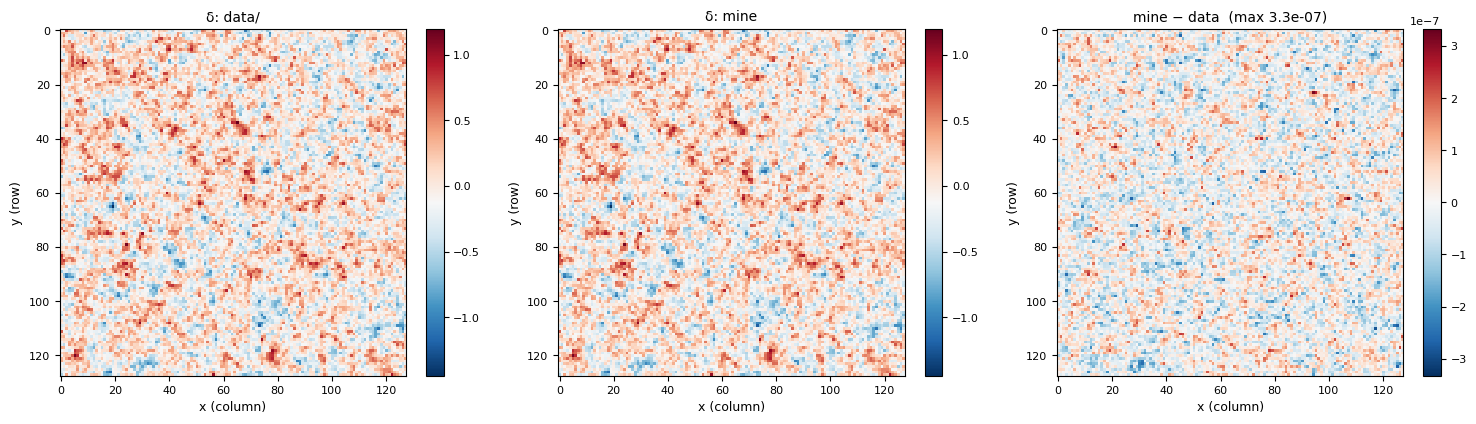

In [10]:
ky = 2 * np.pi * np.fft.fftfreq(N, d=DX)[:, None]       # (N, 1): wavenumber along y (rows), FFT order [1/Mpc]
kx = 2 * np.pi * np.fft.fftfreq(N, d=DX)[None, :]       # (1, N): along x (columns)
kmag = np.sqrt(kx ** 2 + ky ** 2)                       # (N, N): |k| of every FFT cell

A, n1, n2, kb_ = 10 ** TRUE_PW[0], TRUE_PW[1], TRUE_PW[2], 10 ** TRUE_PW[3]
with np.errstate(divide="ignore"):
    P = np.where(kmag <= kb_, A * (kmag / kb_) ** n1, A * (kmag / kb_) ** n2)
P[0, 0] = 0.0

torch.manual_seed(FIELD_SEED)                                   # the global generator, as the simulator does
white = torch.randn((1, N, N), device=DEV)[0].cpu().numpy().astype(np.float64)
delta = np.fft.ifft2(np.fft.fft2(white, norm="ortho") * np.sqrt(P / DX ** 2), norm="ortho").real
compare("δ", delta, D["true_delta"][0])
show3(D["true_delta"][0], delta, "δ", cmap="RdBu_r")

**The P(k) estimator** (the one that makes `pk_obs`): `P = |rfft2(img − mean, ortho)|² · dx dy` per
mode of the **half plane** that `rfft2` returns (columns u = 0…64), averaged in 50 log-spaced bins
from the smallest non-zero |k| to the corner |k|. Bin b holds `edges[b] < |k| ≤ edges[b+1]`; the
smallest |k| sits exactly on `edges[0]` and goes into bin 0; DC is left out. Bins narrower than the
grid spacing at low k hold no mode → NaN. Written once here and used three times.

empty bins: [1, 2, 4, 5, 6, 9, 10, 13]   modes in the first 10 bins: [3, 0, 0, 2, 0, 0, 0, 3, 4, 0]
k-bin centres                  max|mine − data| / max|data| = 6.9e-08
P(k) of δ                      max|mine − data| / max|data| = 3.1e-07


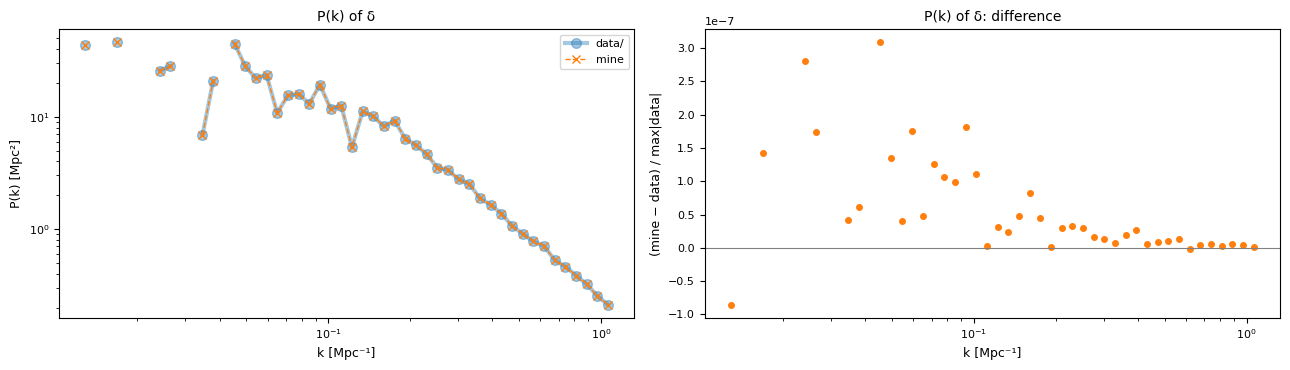

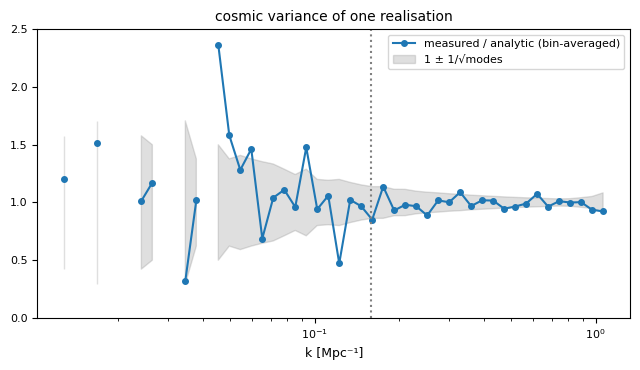

In [11]:
kx_half = 2 * np.pi * np.fft.rfftfreq(N, d=DX)[None, :]           # columns of rfft2 output: u = 0 … 64
k_half = np.sqrt(kx_half ** 2 + ky ** 2)                          # (N, N/2 + 1)
edges = np.logspace(np.log10(k_half[k_half > 0].min()), np.log10(k_half.max()), N_BINS + 1)
k_centres = 0.5 * (edges[:-1] + edges[1:])
bin_of = np.digitize(k_half, edges, right=True) - 1               # edges[b] < k <= edges[b + 1]
bin_of[(k_half > 0) & (bin_of < 0)] = 0                           # k_min, exactly on edges[0]
in_bin = bin_of >= 0                                              # everything but DC
modes = np.bincount(bin_of[in_bin], minlength=N_BINS)

def measure_pk(img):
    p = np.abs(np.fft.rfft2(img - img.mean(), norm="ortho")) ** 2 * DX ** 2
    return np.bincount(bin_of[in_bin], weights=p[in_bin], minlength=N_BINS) / np.where(modes > 0, modes, np.nan)

print("empty bins:", np.flatnonzero(modes == 0).tolist(), "  modes in the first 10 bins:", modes[:10].tolist())
pk_delta = measure_pk(delta)
compare("k-bin centres", k_centres, D["true_k"])
compare("P(k) of δ", pk_delta, D["true_pk_measured"])
show_1d(k_centres, D["true_pk_measured"], pk_delta, "P(k) of δ", "P(k) [Mpc²]")

# and against the analytic P(k): one realisation scatters by ~1/√(modes per bin)
P_half = np.where(k_half <= kb_, A * (np.maximum(k_half, 1e-30) / kb_) ** n1, A * (np.maximum(k_half, 1e-30) / kb_) ** n2)
P_bins = np.bincount(bin_of[in_bin], weights=P_half[in_bin], minlength=N_BINS) / np.where(modes > 0, modes, np.nan)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(k_centres, pk_delta / P_bins, "o-", ms=4, label="measured / analytic (bin-averaged)")
sig = 1 / np.sqrt(np.where(modes > 0, modes, np.nan))
ax.fill_between(k_centres, 1 - sig, 1 + sig, color="gray", alpha=0.25, label="1 ± 1/√modes")
ax.axvline(kb_, color="gray", ls=":"); ax.set(xlabel="k [Mpc⁻¹]", ylim=(0, 2.5), title="cosmic variance of one realisation")
ax.legend(); plt.tight_layout(); plt.show()

**Brightness temperature.** `T_b = T0 x_HI (1 + δ)(1 − T_CMB/T_S)` with x_HI = 1, T_S ≫ T_CMB and
`T0 = 3 h c³ A10 n_H(z) / (32π k_B ν21² (1+z) H(z))` (Furlanetto, Oh & Briggs 2006), Planck 2018.
No foreground is added, so the science image is T_b.

T0 = 26.602 mK   (Furlanetto's approximation: 26.86 mK)
image (T_b)                    max|mine − data| / max|data| = 1.5e-07


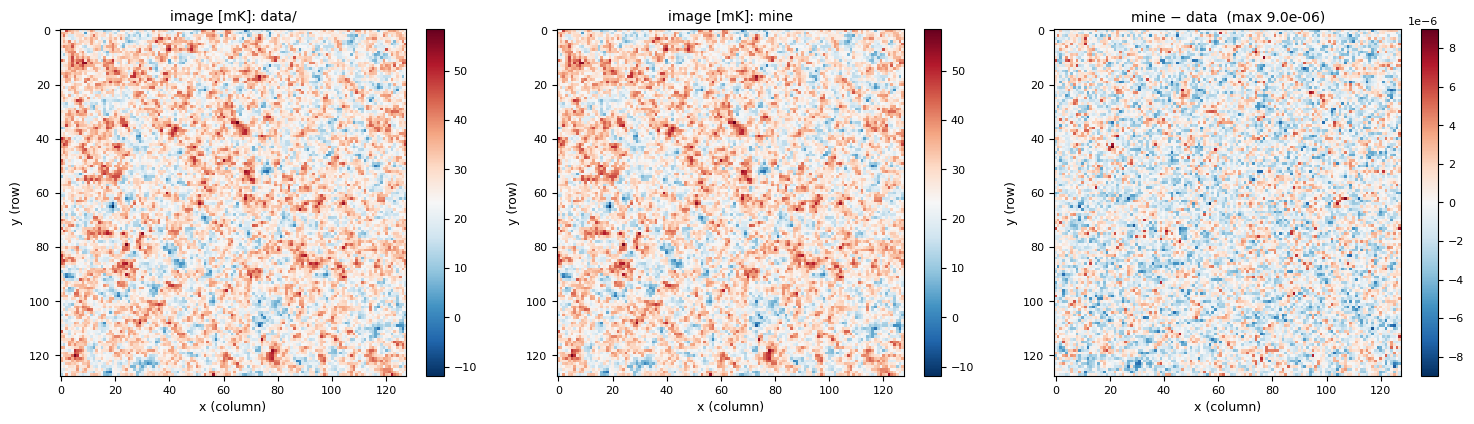

image: mean 26.602 mK, rms 8.222 mK


In [12]:
h_P, c_SI, k_B, A10 = 6.62607015e-34, 2.99792458e8, 1.380649e-23, 2.85e-15
m_p, G_N, MPC = 1.67262192369e-27, 6.67430e-11, 3.0856775814913673e22
H0 = 100e3 * H / MPC                                                          # [1/s]
n_H = (1 - Y_P) * OM_B * 3 * H0 ** 2 / (8 * np.pi * G_N) / m_p * (1 + Z_RED) ** 3   # [1/m³]
H_z = H0 * np.sqrt(OM_M * (1 + Z_RED) ** 3 + 1 - OM_M)                       # [1/s]
T0 = 3 * h_P * c_SI ** 3 * A10 * n_H / (32 * np.pi * k_B * NU21 ** 2 * (1 + Z_RED) * H_z) * 1e3   # [mK]
T0_approx = 27 * (OM_B * H ** 2 / 0.023) * np.sqrt(0.15 / (OM_M * H ** 2) * (1 + Z_RED) / 10)
print(f"T0 = {T0:.3f} mK   (Furlanetto's approximation: {T0_approx:.2f} mK)")

image = T0 * (1 + delta)
compare("image (T_b)", image, D["image"])
show3(D["image"], image, "image [mK]", cmap="RdBu_r")
print(f"image: mean {image.mean():.3f} mK, rms {image.std():.3f} mK")

## 6. The Fourier sky, as an explicit DFT

Instead of `fft2(ifftshift(image))`, the sum written out, with the phase centre (pixel 64, 64) in
the exponent:

$$\tilde I[v, u] = \frac{1}{N}\sum_{y}\sum_{x} \text{image}[y, x]\; e^{-2\pi i\,[\,v\,(y-64) + u\,(x-64)\,]/N},$$

u, v = the signed frequency of the index (0 … 63, −64 … −1). As a matrix:
`E[f, n] = exp(−2πi f (n − 64) / N) / √N`, `Ĩ = E · image · Eᵀ` (E acts on the rows = y → v from the
left and on the columns = x → u from the right). `E` is unitary, so the inverse is `Eᴴ · uv · conj(E)`.

Tests: it equals the project's `fft2(ifftshift(·))`; a point at the phase centre has the same real
value in every cell (zero phase); a point one pixel to the **right** (x + 1) gets a phase that turns
along **u (columns)** only; and the inverse returns the image.

explicit DFT vs fft2(ifftshift(image), ortho): max |difference| = 3.5e-12
DC cell Ĩ[0, 0] = 3405.089 = N × mean(image) = 3405.089
point at the phase centre: every cell = 0.00781 (= 1/N), max |Im| = 0.0e+00
point at x = 65: phase changes along u (columns): True | phase of Ĩ[v=0, u=1] = -0.0491 = −2π/N = -0.0491
round trip E_inv · Ĩ · conj(E) = image: max error 4.8e-13


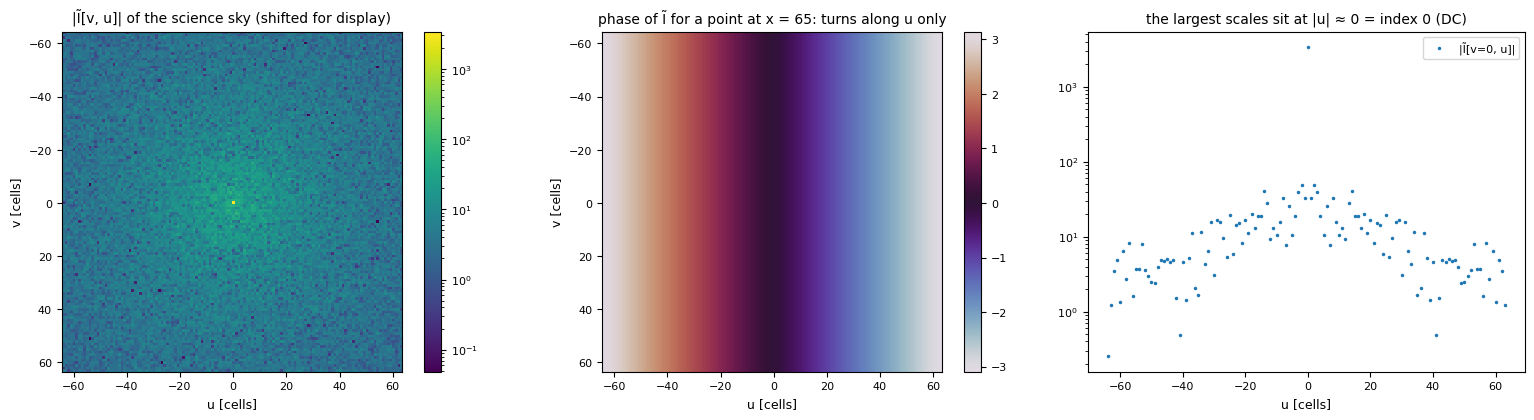

In [13]:
f = np.fft.fftfreq(N, d=1 / N)                              # signed frequency of every index
E = np.exp(-2j * np.pi * np.outer(f, np.arange(N) - C) / N) / np.sqrt(N)
E_inv = E.conj().T                                          # unitary: E_inv @ E = 1
assert np.allclose(E_inv @ E, np.eye(N))

uvimage = E @ image @ E.T                                   # Ĩ[v, u]
print("explicit DFT vs fft2(ifftshift(image), ortho): max |difference| =",
      f"{np.abs(uvimage - np.fft.fft2(np.fft.ifftshift(image), norm='ortho')).max():.1e}")
print(f"DC cell Ĩ[0, 0] = {uvimage[0, 0].real:.3f} = N × mean(image) = {N * image.mean():.3f}")

centre = np.zeros((N, N)); centre[C, C] = 1.0
right = np.zeros((N, N)); right[C, C + 1] = 1.0             # one pixel to the right: x = 65
uv_c, uv_r = E @ centre @ E.T, E @ right @ E.T
print(f"point at the phase centre: every cell = {uv_c[0, 0].real:.5f} (= 1/N), max |Im| = {np.abs(uv_c.imag).max():.1e}")
print("point at x = 65: phase changes along u (columns):", np.allclose(np.angle(uv_r[:, 1]), np.angle(uv_r[0, 1])),
      "| phase of Ĩ[v=0, u=1] =", f"{np.angle(uv_r[0, 1]):.4f} = −2π/N = {-2 * np.pi / N:.4f}")
print("round trip E_inv · Ĩ · conj(E) = image: max error", f"{np.abs(E_inv @ uvimage @ E_inv.T - image).max():.1e}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
im = ax[0].imshow(np.fft.fftshift(np.abs(uvimage)), norm=LogNorm(), extent=ext, interpolation="nearest")
ax[0].set(title="|Ĩ[v, u]| of the science sky (shifted for display)", xlabel="u [cells]", ylabel="v [cells]")
plt.colorbar(im, ax=ax[0], fraction=0.046)
im = ax[1].imshow(np.fft.fftshift(np.angle(uv_r)), cmap="twilight", extent=ext, interpolation="nearest")
ax[1].set(title="phase of Ĩ for a point at x = 65: turns along u only", xlabel="u [cells]", ylabel="v [cells]")
plt.colorbar(im, ax=ax[1], fraction=0.046)
ax[2].plot(np.fft.fftshift(f), np.fft.fftshift(np.abs(uvimage[0])), ".", ms=3, label="|Ĩ[v=0, u]|")
ax[2].set(yscale="log", xlabel="u [cells]", title="the largest scales sit at |u| ≈ 0 = index 0 (DC)"); ax[2].legend()
plt.tight_layout(); plt.show()

## 7. Visibilities → the UV maps `x`

Written the way an interferometer works: every track sample of baseline (i, j) is a visibility

$$V_{ij} = g_i\,g_j^*\;\tilde I[v, u] \qquad\text{and the reversed baseline}\qquad V_{ji} = g_j\,g_i^*\;\tilde I[-v, -u],$$

each weighted by its t integrations and added to its cell (`[v, u]` and `[−v, −u]`). A cell's value
is the **mean visibility** over the integrations that land in it: `x = Σ t V / counts`, 0 on
unsampled cells. (The project writes the same thing as `[Σ t g_i g_j* / counts] × Ĩ`, the
gain-weighted coverage times the sky: a cell's visibilities all sample the same Ĩ. That product is
checked at the end of the cell.)

x (UV maps)                    max|mine − data| / max|data| = 7.6e-07


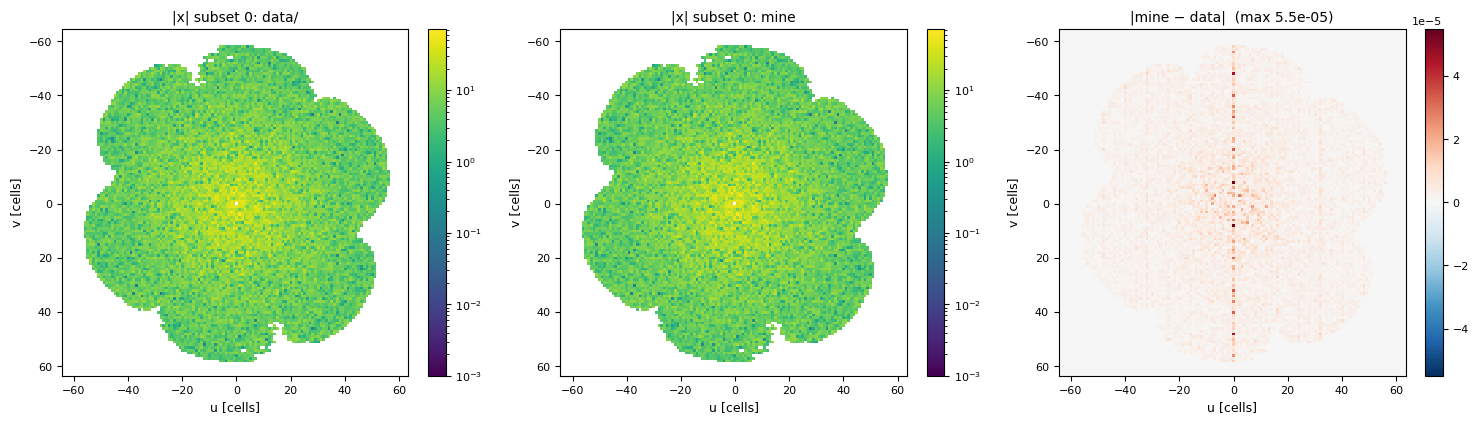

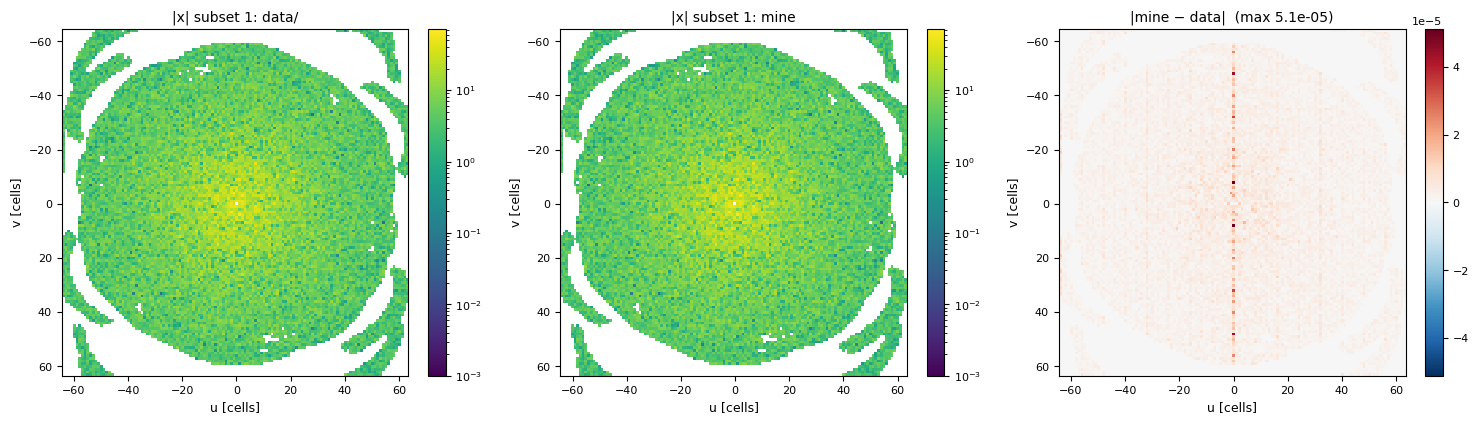

x = g_eff × Ĩ on every cell: True
x Hermitian (x[−v, −u] = conj x[v, u]): True


In [14]:
V_ij = bg[b_s] * uvimage[r_s, c_s]                      # baseline (i, j) at [v, u]
V_ji = np.conj(bg[b_s]) * uvimage[r_m, c_m]             # baseline (j, i) at [−v, −u]
summed = np.zeros((2, N, N), dtype=complex)
np.add.at(summed, (s_s, r_s, c_s), t_s * V_ij)
np.add.at(summed, (s_s, r_m, c_m), t_s * V_ji)
x_uv = np.where(counts > 0, summed / np.where(counts > 0, counts, 1.0), 0.0)

compare("x (UV maps)", x_uv, D["x_obs"])
for s in range(2):
    show3(D["x_obs"][s], x_uv[s], f"|x| subset {s}", uv=True, norm=LogNorm(1e-3, np.abs(x_uv).max()))

# the project's form: effective gain per cell × sky
g_eff = np.zeros((2, N, N), dtype=complex)
np.add.at(g_eff, (s_s, r_s, c_s), t_s * bg[b_s])
np.add.at(g_eff, (s_s, r_m, c_m), t_s * np.conj(bg[b_s]))
g_eff = np.where(counts > 0, g_eff / np.where(counts > 0, counts, 1.0), 0.0)
print("x = g_eff × Ĩ on every cell:", np.allclose(x_uv, g_eff * uvimage, atol=1e-9 * np.abs(x_uv).max()))
print("x Hermitian (x[−v, −u] = conj x[v, u]):",
      np.allclose(x_uv, np.conj(np.roll(x_uv[:, ::-1, ::-1], 1, axis=(1, 2))), atol=1e-9 * np.abs(x_uv).max()))

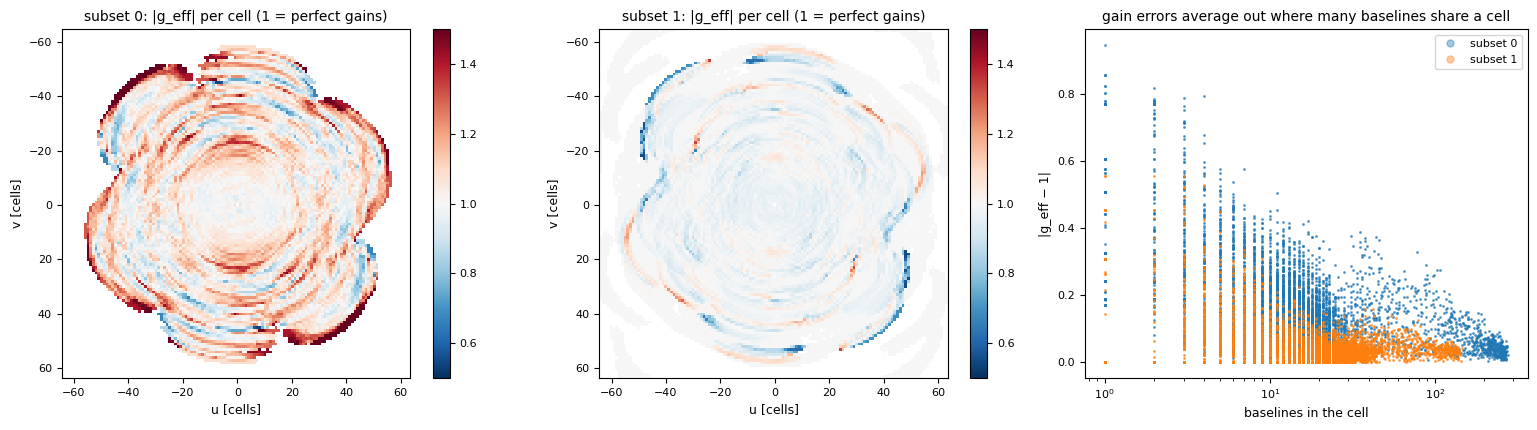

subset 0: median |g_eff − 1| = 0.139
subset 1: median |g_eff − 1| = 0.026


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for s in range(2):
    sampled = counts[s] > 0
    im = ax[s].imshow(np.fft.fftshift(np.where(sampled, np.abs(g_eff[s]), np.nan)), cmap="RdBu_r",
                      norm=TwoSlopeNorm(1, 0.5, 1.5), extent=ext, interpolation="nearest")
    ax[s].set(title=f"subset {s}: |g_eff| per cell (1 = perfect gains)", xlabel="u [cells]", ylabel="v [cells]")
    plt.colorbar(im, ax=ax[s], fraction=0.046)
    ax[2].semilogx(n_bl[s][sampled], np.abs(g_eff[s][sampled] - 1), ".", ms=2, alpha=0.4, label=f"subset {s}")
ax[2].set(xlabel="baselines in the cell", ylabel="|g_eff − 1|", title="gain errors average out where many baselines share a cell")
ax[2].legend(markerscale=5); plt.tight_layout(); plt.show()
for s in range(2):
    print(f"subset {s}: median |g_eff − 1| = {np.median(np.abs(g_eff[s][counts[s] > 0] - 1)):.3f}")

**Result.** `x` built visibility by visibility equals `data/x_obs` to float32 precision (the
largest differences, on the u = 0 column, are float32 round-off of `data/` at the 1e-6 level). Each cell
carries the integration-weighted mean of `g_i g_j*` over its baselines: close to 1 in the dense
centre, far off at the coverage edge where a cell has only one or a few baselines. Subset 0 (first
station i = 0…89) consists almost entirely of baselines with an unknown station; subset 1 is mostly
known–known.

## 8. Dirty images — the explicit inverse DFT, and the orientation

$$\text{obsx}[y, x] = \frac{1}{N}\sum_v\sum_u x[v, u]\; e^{+2\pi i\,[\,v\,(y-64) + u\,(x-64)\,]/N}
= \big(E^\dagger\, x\, \overline{E}\big)[y, x].$$

`x` is Hermitian, so the result is real up to round-off.

max |Im| / max |Re| = 6.9e-16  (round-off)
obsx (dirty images)            max|mine − data| / max|data| = 3.9e-07


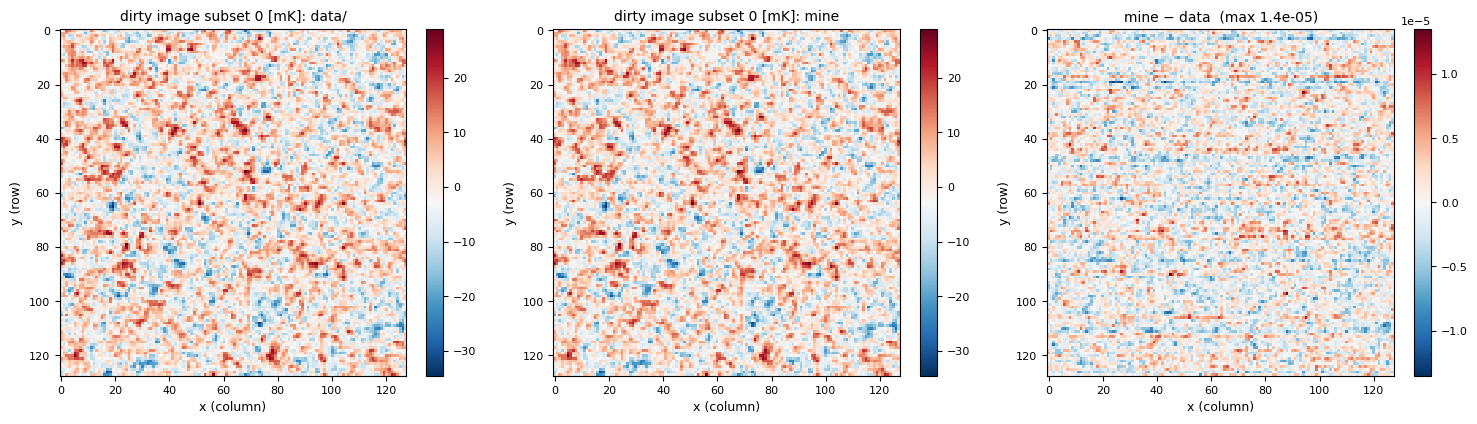

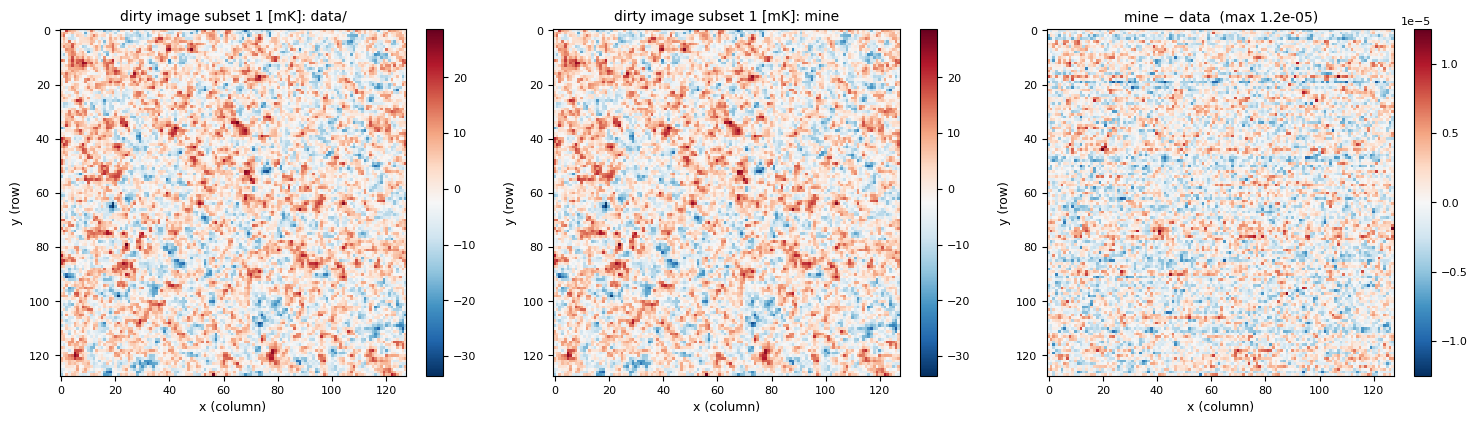

In [16]:
dirty_c = np.stack([E_inv @ x_uv[s] @ E_inv.T for s in range(2)])
print(f"max |Im| / max |Re| = {np.abs(dirty_c.imag).max() / np.abs(dirty_c.real).max():.1e}  (round-off)")
dirty = dirty_c.real
compare("obsx (dirty images)", dirty, D["obsx_obs"])
for s in range(2):
    show3(D["obsx_obs"][s], dirty[s], f"dirty image subset {s} [mK]", cmap="RdBu_r")

**Orientation.** If an axis were swapped or flipped anywhere (tracks, FFT, gridding, inverse), the
dirty image would correlate with a transposed or mirrored sky instead of the sky itself. Two tests:

* the correlation of each dirty image with the true image, its transpose and its flips;
* a single point source at (y = 40, x = 90), observed with the real coverage and unit gains,
  must come back at (40, 90).

subset 0: corr(dirty, sky) = 0.938;  with sky transposed -0.023, flipped up-down +0.029, flipped left-right +0.010
subset 1: corr(dirty, sky) = 0.968;  with sky transposed -0.025, flipped up-down +0.030, flipped left-right +0.013
subset 0: the point comes back at (y, x) = (40, 90)
subset 1: the point comes back at (y, x) = (40, 90)


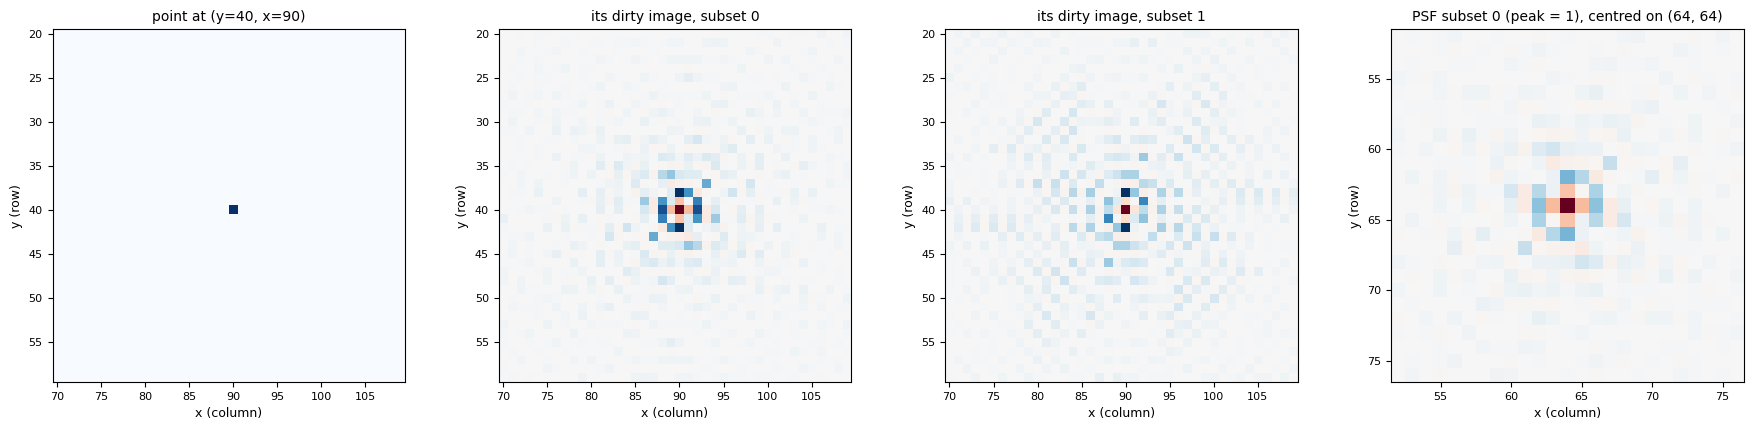

PSF subset 0: peak at (64, 64), strongest negative sidelobe -14.0% of the peak
PSF subset 1: peak at (64, 64), strongest negative sidelobe -10.8% of the peak


In [17]:
sky = image - image.mean()
corr = lambda a, b_: np.corrcoef(a.ravel(), b_.ravel())[0, 1]
for s in range(2):
    print(f"subset {s}: corr(dirty, sky) = {corr(dirty[s], sky):.3f};  with sky transposed {corr(dirty[s], sky.T):+.3f}, "
          f"flipped up-down {corr(dirty[s], sky[::-1]):+.3f}, flipped left-right {corr(dirty[s], sky[:, ::-1]):+.3f}")

point = np.zeros((N, N)); point[40, 90] = 1.0
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
ax[0].imshow(point[20:60, 70:110], extent=[69.5, 109.5, 59.5, 19.5], cmap="Blues"); ax[0].set(title="point at (y=40, x=90)")
for s in range(2):
    d_pt = (E_inv @ ((counts[s] > 0) * (E @ point @ E.T)) @ E_inv.T).real
    print(f"subset {s}: the point comes back at (y, x) = {tuple(int(i_) for i_ in np.unravel_index(np.argmax(d_pt), d_pt.shape))}")
    ax[1 + s].imshow(d_pt[20:60, 70:110], extent=[69.5, 109.5, 59.5, 19.5], cmap="RdBu_r",
                     norm=TwoSlopeNorm(0)); ax[1 + s].set(title=f"its dirty image, subset {s}")
psf = (E_inv @ (counts[0] > 0).astype(float) @ E_inv.T).real
ax[3].imshow(psf[C - 12:C + 13, C - 12:C + 13] / psf.max(), cmap="RdBu_r", norm=TwoSlopeNorm(0, -0.3, 1),
             extent=[C - 12.5, C + 12.5, C + 12.5, C - 12.5]); ax[3].set(title="PSF subset 0 (peak = 1), centred on (64, 64)")
for a in ax:
    a.set(xlabel="x (column)", ylabel="y (row)")
plt.tight_layout(); plt.show()
for s in range(2):
    p_ = (E_inv @ (counts[s] > 0).astype(float) @ E_inv.T).real
    print(f"PSF subset {s}: peak at {tuple(int(i_) for i_ in np.unravel_index(np.argmax(p_), p_.shape))}, strongest negative sidelobe {p_.min() / p_.max():.1%} of the peak")

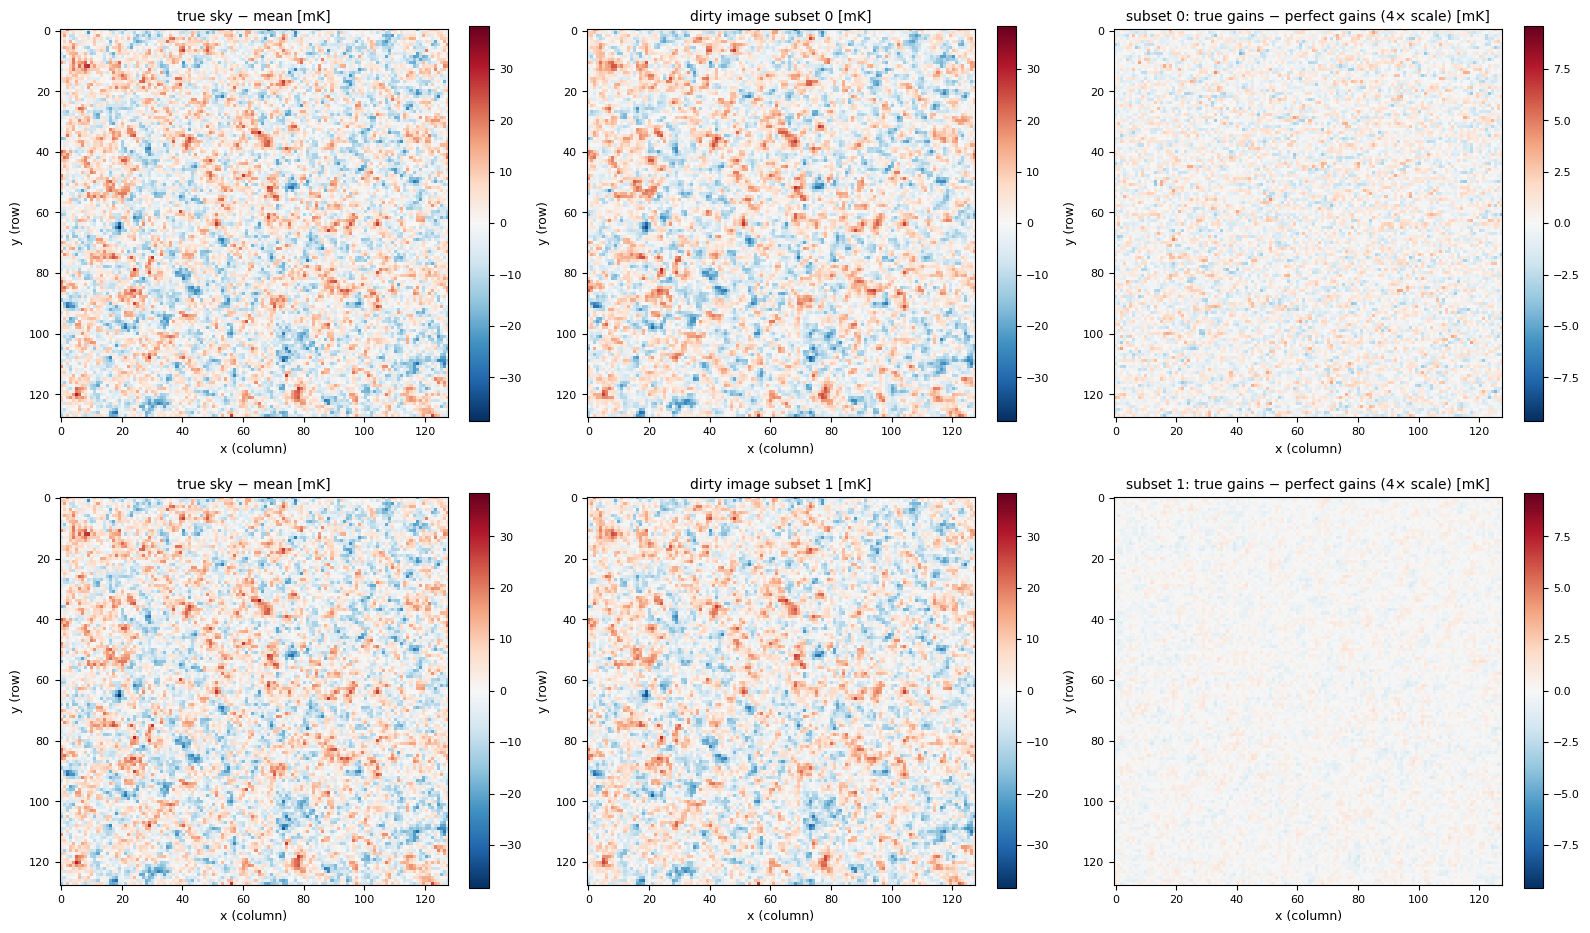

subset 0: corr(perfect-gain dirty, sky) = 0.947;  rms sky 8.22 mK, rms of the gain error 1.15 mK (14%)
subset 1: corr(perfect-gain dirty, sky) = 0.970;  rms sky 8.22 mK, rms of the gain error 0.45 mK (5%)


In [18]:
# what the gains do to the image: observe the same sky with perfect gains (g = 1) for comparison
dirty_unit = np.stack([(E_inv @ np.where(counts[s] > 0, uvimage, 0) @ E_inv.T).real for s in range(2)])
v_ = np.abs(sky).max()
fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))
for s in range(2):
    for a, img, t_ in ((ax[s, 0], sky, "true sky − mean"), (ax[s, 1], dirty[s], f"dirty image subset {s}"),
                       (ax[s, 2], dirty[s] - dirty_unit[s], f"subset {s}: true gains − perfect gains (4× scale)")):
        lim = v_ if a is not ax[s, 2] else v_ / 4
        im = a.imshow(img, cmap="RdBu_r", vmin=-lim, vmax=lim); a.set(title=t_ + " [mK]", xlabel="x (column)", ylabel="y (row)")
        plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()
for s in range(2):
    print(f"subset {s}: corr(perfect-gain dirty, sky) = {corr(dirty_unit[s], sky):.3f};  rms sky {sky.std():.2f} mK, "
          f"rms of the gain error {np.std(dirty[s] - dirty_unit[s]):.2f} mK ({np.std(dirty[s] - dirty_unit[s]) / sky.std():.0%})")

**Result.** The dirty images built with the explicit inverse DFT equal `data/obsx_obs`. They
correlate strongly with the true sky and not with its transpose or mirror images, and the point
source returns to its own pixel: **rows, columns, the FFT order of the tracks and the phase centre
are consistent end to end.** The difference between true and perfect gains (right column) is
noise-like, larger in subset 0, whose cells mix many corrupted baselines.

## 9. P(k) of the dirty images → `pk_obs` (the Stage-2 data)

pk_obs                         max|mine − data| / max|data| = 6.2e-07


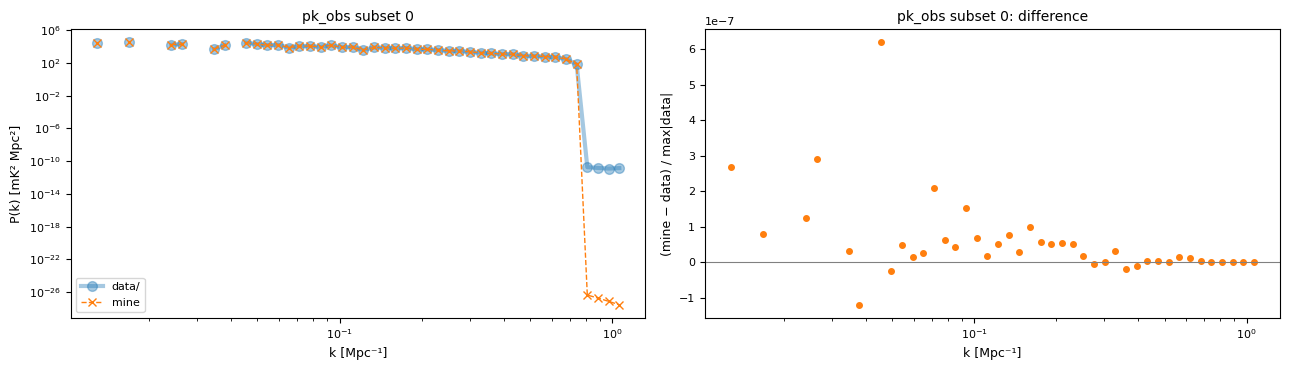

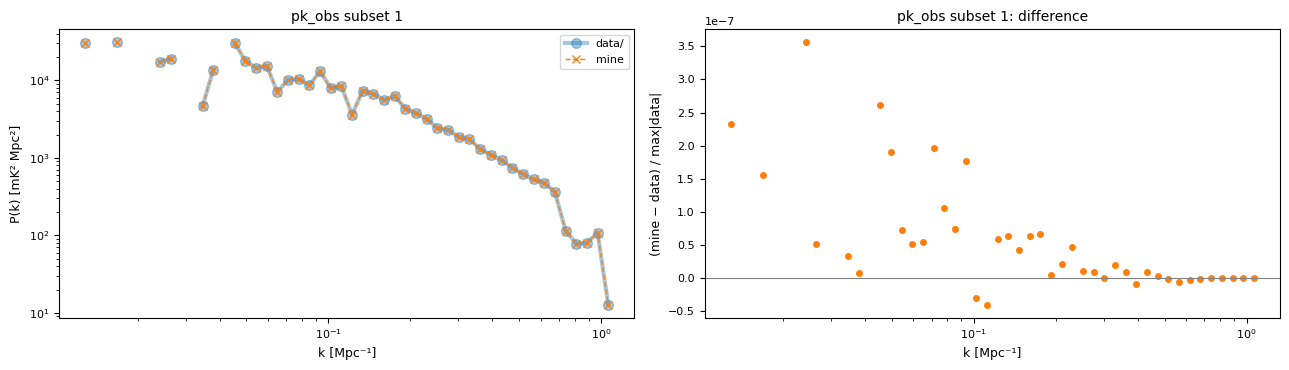

In [19]:
pk_obs = np.stack([measure_pk(dirty[s]) for s in range(2)])
compare("pk_obs", pk_obs, D["pk_obs"])
for s in range(2):
    show_1d(k_centres, D["pk_obs"][s], pk_obs[s], f"pk_obs subset {s}", "P(k) [mK² Mpc²]")

P(k) of the image = T0² × P(k) of δ (T0² = 707.7): True


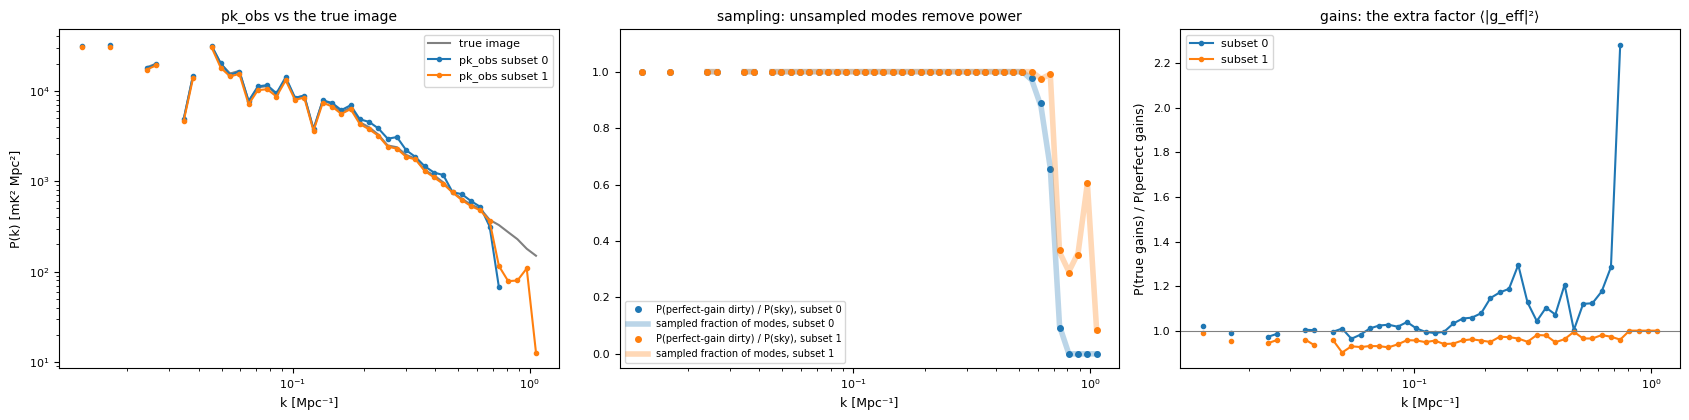

subset 0: P(true gains) / P(perfect gains) = 0.964 … 2.284;  round-off-only bins: [46, 47, 48, 49]
subset 1: P(true gains) / P(perfect gains) = 0.902 … 1.000;  round-off-only bins: []


In [20]:
# why pk_obs differs from the P(k) of the sky: T0², the sampling, the gains
pk_image = measure_pk(image)
pk_unit = np.stack([measure_pk(dirty_unit[s]) for s in range(2)])
samp = np.stack([np.bincount(bin_of[in_bin], weights=(counts[s][:, :C + 1] > 0)[in_bin], minlength=N_BINS)
                 / np.where(modes > 0, modes, np.nan) for s in range(2)])        # sampled fraction of the modes of each bin
print(f"P(k) of the image = T0² × P(k) of δ (T0² = {T0 ** 2:.1f}):", np.allclose(pk_image, T0 ** 2 * pk_delta, equal_nan=True))
roundoff = D["pk_obs"] <= 1e-11 * np.nanmax(D["pk_obs"], axis=1, keepdims=True)  # no sampled mode: FFT round-off only
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].loglog(k_centres, pk_image, color="gray", label="true image")
for s in range(2):
    ax[0].loglog(k_centres[~roundoff[s]], pk_obs[s][~roundoff[s]], "o-", ms=3, label=f"pk_obs subset {s}")
    ax[1].semilogx(k_centres, pk_unit[s] / pk_image, "o", ms=4, label=f"P(perfect-gain dirty) / P(sky), subset {s}")
    ax[1].semilogx(k_centres, samp[s], lw=4, alpha=0.3, color=f"C{s}", label=f"sampled fraction of modes, subset {s}")
    ax[2].semilogx(k_centres[~roundoff[s]], (pk_obs[s] / pk_unit[s])[~roundoff[s]], "o-", ms=3, label=f"subset {s}")
ax[0].set(xlabel="k [Mpc⁻¹]", ylabel="P(k) [mK² Mpc²]", title="pk_obs vs the true image"); ax[0].legend()
ax[1].set(xlabel="k [Mpc⁻¹]", title="sampling: unsampled modes remove power", ylim=(-0.05, 1.15)); ax[1].legend(fontsize=7)
ax[2].axhline(1, color="gray", lw=0.8)
ax[2].set(xlabel="k [Mpc⁻¹]", ylabel="P(true gains) / P(perfect gains)", title="gains: the extra factor ⟨|g_eff|²⟩"); ax[2].legend()
plt.tight_layout(); plt.show()
for s in range(2):
    r_ = (pk_obs[s] / pk_unit[s])[~roundoff[s]]
    print(f"subset {s}: P(true gains) / P(perfect gains) = {np.nanmin(r_):.3f} … {np.nanmax(r_):.3f};  "
          f"round-off-only bins: {np.flatnonzero(roundoff[s]).tolist()}")

**Result.** `pk_obs` equals `data/pk_obs`. (In subset 0 the four highest bins contain no sampled mode:
there both are pure FFT round-off, ~1e-11 in float32 `data/` and ~1e-26 here — zero either way.) Relative to the P(k) of δ it carries three factors:

1. **T0²** (mK units), exact;
2. **the sampled fraction of each bin** (middle): the perfect-gain dirty image keeps exactly the
   sampled modes, so its P(k) / P(sky) follows the fraction of sampled modes — 1 at low k, falling
   where the coverage runs out, 0 in the bins with no sampled mode (the round-off-only bins, which
   the Stage-2 embedding drops);
3. **the gains** (right): each mode × |g_eff|² of its cell. In subset 0 this is ≈ 1 at low k but
   rises at higher k, where cells hold few baselines and the errors do not average out
   (⟨|g|²⟩ > |⟨g⟩|²); subset 1 is biased slightly down. This scale-dependent imprint is degenerate
   with the P(k) shape, which is why Stage 2 also sees `V_ref`.

## 10. The calibrator: `S_ref`, `V_ref`, and the gains back

The calibration path uses each baseline on its own (no UV map): one number per baseline, the mean of
the Fourier sky over its track,

$$S[i,j] = \frac{\sum_\text{track} t\,\tilde I[v,u]}{\sum_\text{track} t},\qquad
S[j,i] = \frac{\sum_\text{track} t\,\tilde I[-v,-u]}{\sum_\text{track} t},\qquad S[i,i] = 0,$$

(DC samples dropped, 0 for baselines never on the grid), and with constant gains
`V[i, j] = g_i S[i, j] conj(g_j)`. The calibrator is a 2.7 mK Gaussian, σ = 0.3 px, at pixel (64, 64).

S_ref                          max|mine − data| / max|data| = 2.8e-07
V_ref                          max|mine − data| / max|data| = 2.4e-07


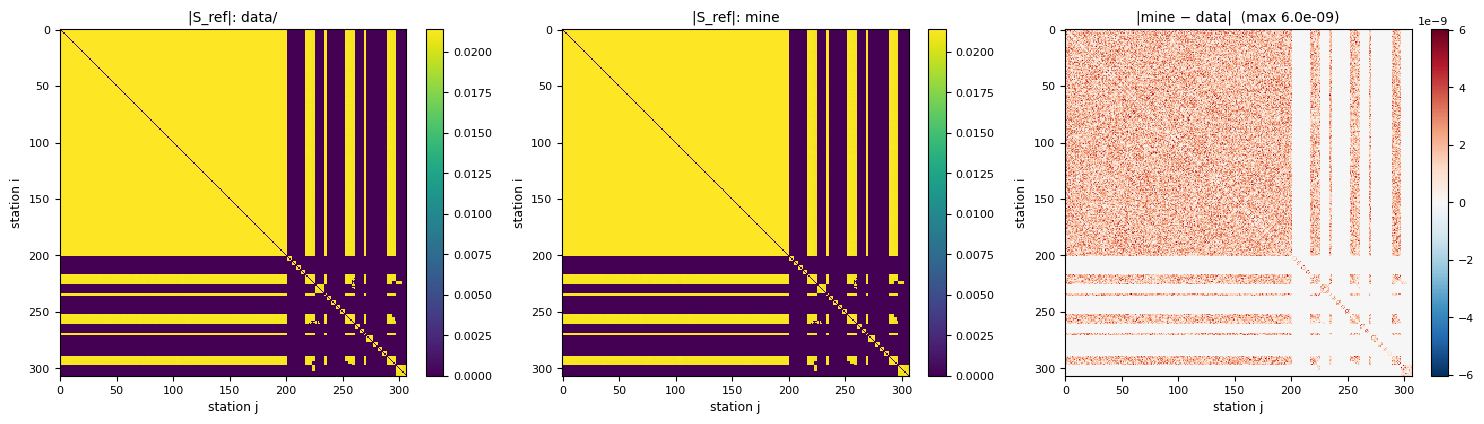

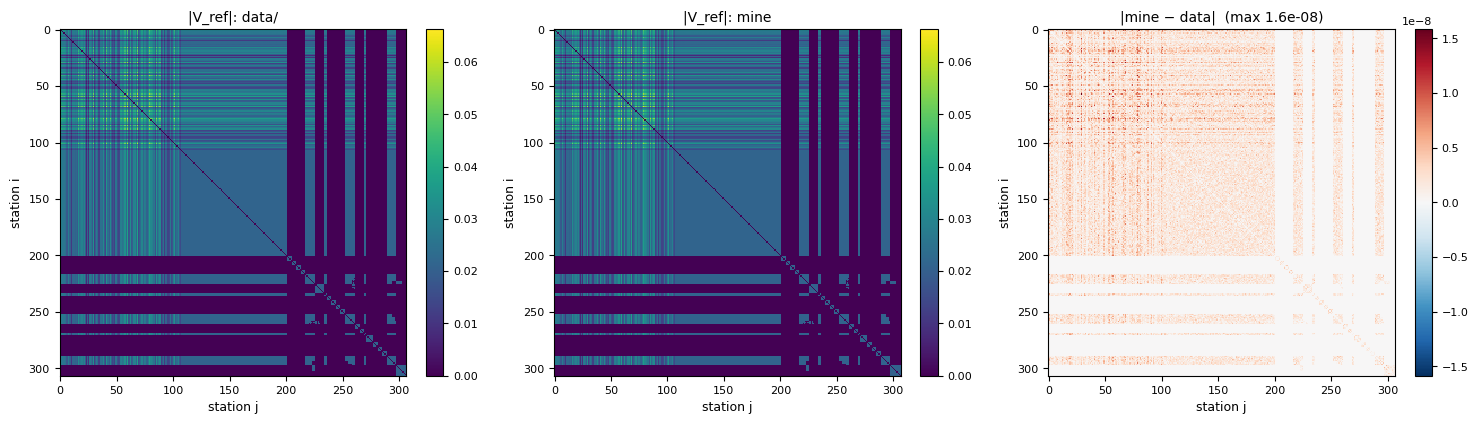

S_ref on observed baselines: |S| 0.02078 … 0.02142, max |phase| 3.0e-19 rad (calibrator on the phase centre → real);  Hermitian: max |S − Sᴴ| = 2.6e-22


In [21]:
def sky_matrix(uv):
    s_ij = np.zeros(K, dtype=complex); np.add.at(s_ij, b_s, t_s * uv[r_s, c_s])    # track of (i, j): +u
    s_ji = np.zeros(K, dtype=complex); np.add.at(s_ji, b_s, t_s * uv[r_m, c_m])    # track of (j, i): −u
    n = np.where(n_per_bl > 0, n_per_bl, np.inf)
    S = np.zeros((NANT, NANT), dtype=complex)
    S[I, J], S[J, I] = s_ij / n, s_ji / n
    return S

calibrator = CAL_FLUX * np.exp(-((xx - C) ** 2 + (yy - C) ** 2) / (2 * CAL_SIGMA ** 2))
S_ref = sky_matrix(E @ calibrator @ E.T)
V_ref = g[:, None] * S_ref * np.conj(g)[None, :]
compare("S_ref", S_ref, D["S_ref"])
compare("V_ref", V_ref, D["V_ref_obs"])
show3(D["S_ref"], S_ref, "|S_ref|", labels=("station j", "station i"))
show3(D["V_ref_obs"], V_ref, "|V_ref|", labels=("station j", "station i"))
nz = S_ref[S_ref != 0]
print(f"S_ref on observed baselines: |S| {np.abs(nz).min():.5f} … {np.abs(nz).max():.5f}, max |phase| {np.abs(np.angle(nz)).max():.1e} rad "
      f"(calibrator on the phase centre → real);  Hermitian: max |S − Sᴴ| = {np.abs(S_ref - S_ref.conj().T).max():.1e}")

z from the first row of data/V_ref_obs: max |z_back − z_true| = 1.6e-07


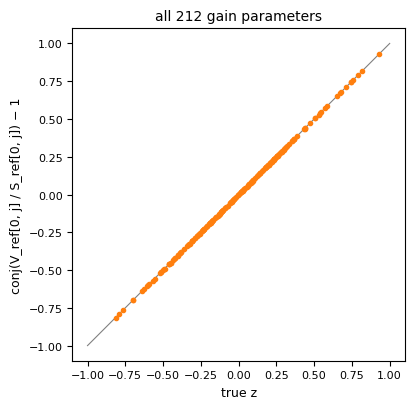

In [22]:
# with S_ref known and g_0 = 1, the first row gives every unknown gain: V[0, j] = S[0, j] conj(g_j)
g_back = np.conj(D["V_ref_obs"][0, 1:1 + N_UNK] / D["S_ref"][0, 1:1 + N_UNK])
z_back = np.stack([g_back.real - 1, g_back.imag], axis=-1).reshape(1, -1)
print(f"z from the first row of data/V_ref_obs: max |z_back − z_true| = {np.abs(z_back - D['true_z']).max():.1e}")
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.plot([-1, 1], [-1, 1], color="gray", lw=0.8); ax.plot(D["true_z"][0], z_back[0], ".", color="C1")
ax.set(xlabel="true z", ylabel="conj(V_ref[0, j] / S_ref[0, j]) − 1", aspect="equal", title="all 212 gain parameters")
plt.tight_layout(); plt.show()

## 11. The dense science path: `S_obs`, `V_dense`

`gen_mock_data.py` also passes the science sky through the per-baseline path (not used by falcon;
disabled in `config.yml`).

S_obs                          max|mine − data| / max|data| = 3.1e-07
V_dense                        max|mine − data| / max|data| = 2.8e-07


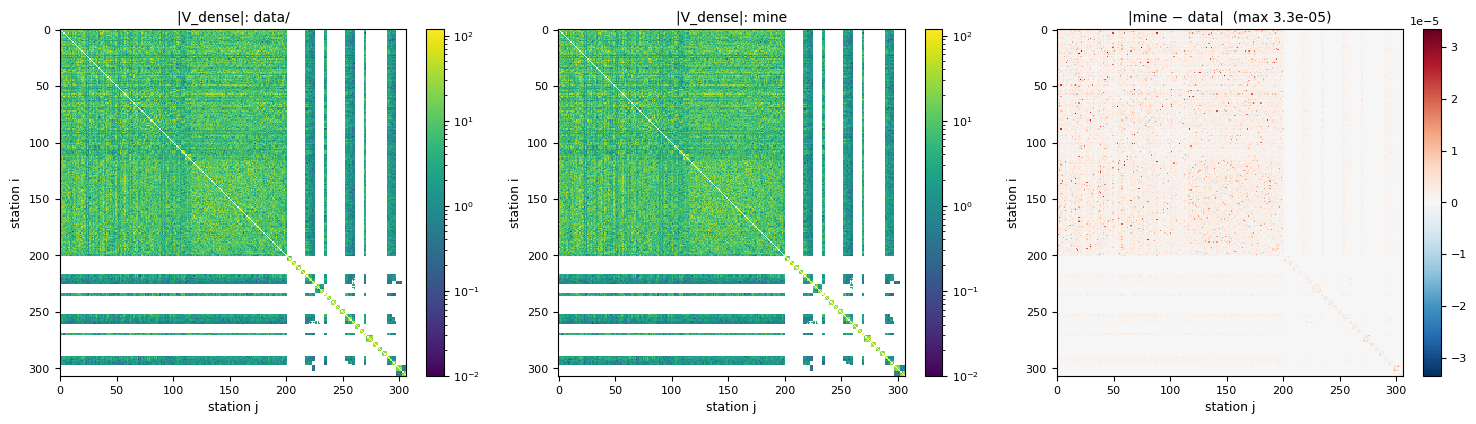

In [23]:
S_obs = sky_matrix(uvimage)
V_dense = g[:, None] * S_obs * np.conj(g)[None, :]
compare("S_obs", S_obs, D["S_obs"])
compare("V_dense", V_dense, D["V_dense_obs"])
show3(D["V_dense_obs"], V_dense, "|V_dense|", labels=("station j", "station i"), norm=LogNorm(1e-2, np.abs(V_dense).max()))

## Summary

In [24]:
TOL = 1e-5      # float32 data agree at ~1e-7; a wrong axis, sign, shift or factor gives order 1
print(f"{'quantity':30s} {'max|mine − data| / max|data|':>30s}")
for name, rel in results:
    print(f"{name:30s} {rel:30.1e}   {'ok' if rel < TOL else 'DIFFERS'}")
bad = [name for name, rel in results if not rel < TOL]
assert not bad, f"differ from data/: {bad}"
print(f"\nall {len(results)} comparisons agree with data/ to < {TOL:g}")

quantity                         max|mine − data| / max|data|
z (redrawn from seed 99)                              0.0e+00   ok
δ                                                     2.3e-07   ok
k-bin centres                                         6.9e-08   ok
P(k) of δ                                             3.1e-07   ok
image (T_b)                                           1.5e-07   ok
x (UV maps)                                           7.6e-07   ok
obsx (dirty images)                                   3.9e-07   ok
pk_obs                                                6.2e-07   ok
S_ref                                                 2.8e-07   ok
V_ref                                                 2.4e-07   ok
S_obs                                                 3.1e-07   ok
V_dense                                               2.8e-07   ok

all 12 comparisons agree with data/ to < 1e-05


**In one paragraph.** The tracks file is the layout + Earth rotation gridded in FFT order (rows = v,
columns = u, DC at `[0, 0]`), the same grid `fft2` uses for the image. The 212 numbers `z` give the
station gains. The power-spectrum parameters colour seeded white noise into δ, which becomes a
T0 (1 + δ) mK sky. Every baseline sample is a visibility `g_i g_j* Ĩ(u)` (and the reversed baseline
at −u); averaging them per cell gives the UV maps `x`, whose inverse DFT (phase centre at pixel 64)
is the dirty image — the true sky seen through the coverage, in the right orientation. Its P(k),
`pk_obs`, is T0² P_δ × (sampled fraction) × ⟨|g_eff|²⟩. In parallel the calibrator, baseline by
baseline, gives `V_ref = g S_ref g*`, from which the gains can be read off exactly. Every one of these
products, recomputed here independently of `src/`, matches `data/`.